***Week 5 Jupyter Notebook — Assignment Instructions***

Each week, you will apply the concepts of that week to your Integrated Capstone Project’s dataset. In preparation for Milestone One, create a Jupyter Notebook (similar to in Module B, Semester Two) that illustrates these lessons. There are no specific questions to answer in your Jupyter Notebook files in this course; your general goal is to analyze your data using the methods you have learned about in this course and in this program and draw interesting conclusions.

For Week 5, include concepts such as support vector machines, the kernel trick, and regularization for support vector machines. Complete your Jupyter Notebook homework by 11:59pm ET on Sunday.

In Week 7, findings will be compiled for Milestone One. The referenced Milestone One rubric/link was not supplied; this notebook covers the weekly instructions above.

# Week 5: Support vector machines, kernels, and regularization

Calvin Baker · DX799 Integrated Capstone · Three independent dataset analyses

## tl;dr

- **Loan_Default.csv** — recorded Status 1: **RBF SVM**, test AUC **0.590**, AP **0.351**, F1 at the validation cutoff **0.371**, test n=2,400.
- **accepted_2007_to_2018Q4.csv** — charged off among resolved 2015 36-month loans: **Linear SVM**, test AUC **0.534**, AP **0.172**, F1 at the validation cutoff **0.239**, test n=2,400.
- **bank_customers.csv** — checking account versus savings/CD: **Polynomial SVM**, test AUC **0.667**, AP **0.911**, F1 at the validation cutoff **0.000**, test n=8.

Unweighted SVM results are retained, including weak lending ranking and the failed bank cutoff. The later balanced-class check is exploratory and uses no additional test evaluation.

All three CSVs are analyzed independently. Loan samples and partitions are matched between Weeks 5 and 6; bank conclusions rest on just 39 eligible records. Read the leakage, sampling and outcome limitations below before interpreting the scores.

## Context & Methods

**Question:** Does a nonlinear margin improve classification over a linear margin on each capstone dataset, and how does regularization affect generalization?

For labels $t_i\in\{-1,+1\}$, the soft-margin SVM solves
$$\min_{w,b,\xi}\frac12\lVert w\rVert^2+C\sum_i\xi_i,
\quad t_i(w^T\phi(x_i)+b)\ge1-\xi_i,\quad\xi_i\ge0.$$
The first term favors a wider margin; slack permits violations. **Smaller C means stronger regularization**; larger C penalizes violations more heavily. A support vector has a nonzero dual weight and contributes to the fitted decision function. Many support vectors can reflect overlapping classes; their count alone is not a measure of model quality.

The **kernel trick** computes $K(x,z)=\phi(x)^T\phi(z)$ without explicitly constructing the mapped features. We compare linear $x^Tz$, degree-two polynomial $(\gamma x^Tz+1)^2$, and RBF $\exp(-\gamma\lVert x-z\rVert^2)$ kernels. Larger gamma makes RBF influence more local and can overfit. C and gamma interact, so both are searched. Numeric scaling matters because distances and margins depend on feature units. One-hot indicators remain 0/1; all preparation is learned within each training fold. Full one-hot encoding avoids arbitrary distance changes from a dropped reference category.

SVM margins are **scores, not probabilities**. ROC AUC/AP use these scores directly; log loss and probability calibration are intentionally outside this margin-based experiment. Zero is the conventional margin cutoff; validation F1 supplies an additional illustrative operating rule.

### Key Assumptions and evaluation plan

- Each CSV is an independent source; there are no joins between unrelated people or loans. The source paths are `DATA/Loan_Default.csv`, `DATA/accepted_2007_to_2018Q4.csv`, and `DATA/bank_customers.csv`.
- Continue Week 4's classification targets and conservative predictor sets. For repeatable kernel experiments, take **12,000 uniformly sampled rows** per loan dataset (or all rows if fewer). Week 6 uses exactly the same samples and partitions. This differs from Week 4's full Loan_Default population and 24,000-row LendingClub sample; do **not** attribute cross-week score changes solely to algorithms.
- Loans use a seed-42, stratified 60% train / 20% validation / 20% test split. Bank records use Week 4's account-group split and three-fold group CV. No account crosses partitions or CV folds. Loan IDs identify rows, not verified unique borrowers; random splits assume sufficient row independence.
- Training-only three-fold CV chooses each family's parameters by mean **ROC AUC**; validation AUC chooses the family. AP and fold variation are shown for context. In a tie, the first listed family wins. Finite grids may select an edge; search ranges would need expansion inside training for further optimization.
- Select the F1 cutoff only on validation. Freeze the training-fitted model and cutoff, then evaluate on test once. **No development-set refit** is performed, preserving the score scale used for threshold selection. Prespecified family and fixed-C logistic baselines are also shown on test, without choosing another winner afterward.
- Accuracy alone is misleading with imbalance. Report AUC, AP, prevalence, precision, recall, F1, balanced accuracy, predicted-positive counts and exact confusion counts. A prior-probability/majority baseline has AUC 0.5 and AP equal to prevalence. AUC measures ranking; a high AUC does not guarantee useful decisions or calibrated probabilities.
- The bank reference date remains **2026-09-26** for comparability with prior weeks; it is not today's date. It yields 39 eligible records. Exclusion reasons can overlap. Bank estimates demonstrate methods and are too small for reliable population conclusions.
- Original CSVs stay unchanged. Use the repository's `requirements-notebooks.txt`, then **Restart Kernel → Run All**. Each notebook is self-contained and prints the environment versions; no hidden fitted artifacts are required.

### 1. Set up the environment

Run from this repository or its parent workspace. Fixed seeds and bounded numerical threads support reproducibility.

In [1]:
from pathlib import Path
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import sklearn
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

# A fixed seed and bounded numerical threads make the workflow repeatable.
SEED = 42
thread_limit = threadpool_limits(limits=1)
warnings.filterwarnings('error', category=ConvergenceWarning)
pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', lambda value: f'{value:,.4f}')
plt.rcParams.update({'figure.figsize': (10, 4.5), 'figure.dpi': 115,
                     'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.18, 'axes.axisbelow': True})
BLUE, ORANGE, GRAY = '#245E91', '#B96520', '#50545A'

# Support opening from the repository itself or its parent workspace.
data_candidates = [Path.cwd() / 'DATA',
                   Path.cwd() / 'Data-Science-Capstone-DX799' / 'DATA']
DATA_DIR = next((p for p in data_candidates if p.is_dir()), None)
if DATA_DIR is None:
    raise FileNotFoundError('Open this notebook from the repository or its parent; DATA is required.')
display(pd.Series({'Python': platform.python_version(), 'pandas': pd.__version__,
                   'NumPy': np.__version__, 'scikit-learn': sklearn.__version__,
                   'SciPy': scipy.__version__, 'seed': SEED}, name='Execution environment'))
from sklearn.model_selection import StratifiedKFold, GroupShuffleSplit, GroupKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
    balanced_accuracy_score, precision_score, recall_score, f1_score,
    roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
import time
SAMPLE_SIZE = 12_000
results = []

Python          3.13.5
pandas           3.0.0
NumPy            2.4.1
scikit-learn     1.8.0
SciPy           1.17.0
seed                42
Name: Execution environment, dtype: object

### 2. Define shared, unfitted tools

Reuse functions only. Each dataset gets its own split, preprocessing, tuning, fitted estimators and results.

In [2]:
def extra_split(X, y, groups=None, classification=False):
    """Use a row split for loans and account-group separation for bank records."""
    if groups is None:
        development, test = train_test_split(np.arange(len(X)), test_size=0.20,
            random_state=SEED, stratify=y if classification else None)
        train, valid = train_test_split(development, test_size=0.25, random_state=SEED,
            stratify=y.iloc[development] if classification else None)
        cv = (StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
              if classification else KFold(n_splits=3, shuffle=True, random_state=SEED))
        folds = list(cv.split(X.iloc[train], y.iloc[train]))
    else:
        development, test = next(GroupShuffleSplit(n_splits=1, test_size=0.20,
            random_state=SEED).split(X, y, groups))
        train_local, valid_local = next(GroupShuffleSplit(n_splits=1, test_size=0.25,
            random_state=SEED).split(X.iloc[development], y.iloc[development], groups.iloc[development]))
        train, valid = development[train_local], development[valid_local]
        # Do not split records from the same account across CV folds either.
        folds = list(GroupKFold(n_splits=3).split(X.iloc[train], y.iloc[train], groups.iloc[train]))
        sets = [set(groups.iloc[index]) for index in [train, valid, test]]
        assert not (sets[0] & sets[1] or sets[0] & sets[2] or sets[1] & sets[2])
    assert len(set(train) | set(valid) | set(test)) == len(X)
    if classification:
        for index in [train, valid, test]:
            assert y.iloc[index].nunique() == 2, 'Both classes are required in every evaluation split.'
        for fit, holdout in folds:
            assert y.iloc[train].iloc[fit].nunique() == 2
            assert y.iloc[train].iloc[holdout].nunique() == 2
    return train, valid, test, development, folds


def prepare(numeric, categorical, scale=True):
    steps = [('impute', SimpleImputer(strategy='median'))]
    if scale:
        steps.append(('scale', StandardScaler()))
    transformers = [('numeric', Pipeline(steps), numeric)]
    if categorical:
        transformers.append(('categorical', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), categorical))
    return ColumnTransformer(transformers, verbose_feature_names_out=False)

def pipeline(model, scale=True):
    return Pipeline([('prepare', prepare(numeric, categorical, scale)), ('model', model)])

def score_values(model, data):
    if hasattr(model, 'decision_function'):
        return model.decision_function(data)
    return model.predict_proba(data)[:, 1]

def metrics(actual, scores, prediction):
    return {'ROC AUC': roc_auc_score(actual, scores),
            'Average precision': average_precision_score(actual, scores),
            'Accuracy': accuracy_score(actual, prediction),
            'Balanced accuracy': balanced_accuracy_score(actual, prediction),
            'Precision': precision_score(actual, prediction, zero_division=0),
            'Recall': recall_score(actual, prediction, zero_division=0),
            'F1': f1_score(actual, prediction, zero_division=0),
            'Predicted positive': int(np.sum(prediction))}

def tune(model, grid, scale=True):
    search = GridSearchCV(pipeline(model, scale), grid, cv=folds,
        scoring={'auc':'roc_auc','ap':'average_precision'}, refit='auc',
        n_jobs=1, return_train_score=True, error_score='raise')
    start = time.perf_counter()
    search.fit(X_train, y_train)
    elapsed = time.perf_counter() - start
    estimator = search.best_estimator_
    row = {'CV AUC': search.best_score_,
           'CV AUC SD': search.cv_results_['std_test_auc'][search.best_index_],
           'Train AUC': roc_auc_score(y_train, score_values(estimator, X_train)),
           'Validation AUC': roc_auc_score(y_valid, score_values(estimator, X_valid)),
           'Validation AP': average_precision_score(y_valid, score_values(estimator, X_valid)),
           'Fit seconds': elapsed, 'Parameters': search.best_params_}
    return search, row

## A. Loan_Default.csv — independent analysis

**Outcome:** recorded `Status=1` versus 0, with all valid statuses eligible before uniform sampling. Use loan amount, income, credit score, term, loan type, purpose and occupancy. Exclude identifiers, sensitive demographic fields, pricing, property/LTV/DTI fields and credit_type because the prior leakage audit found status-linked artifacts. Missingness in included fields can still carry collection artifacts; removing the worst fields does not prove leakage-free future prediction. The observation window/status semantics are not documented in the supplied files.

### A1. Load and reconcile source data

In [3]:
dataset_name = 'Loan_Default.csv'
outcome_label = 'recorded Status 1'
source_frame = pd.read_csv(DATA_DIR / dataset_name)
assert source_frame['ID'].notna().all() and source_frame['ID'].is_unique
assert source_frame['Status'].notna().all() and set(source_frame['Status'].unique()) == {0,1}
assert not source_frame.duplicated().any()
# Uniform sampling is independent of outcome. Preserve original indices for audits.
frame = source_frame.sample(n=min(SAMPLE_SIZE, len(source_frame)), random_state=SEED).copy()
numeric = ['loan_amount', 'income', 'Credit_Score', 'term']
categorical = ['loan_type', 'loan_purpose', 'occupancy_type']
X = frame[numeric + categorical].copy()
for name in categorical:
    X[name] = X[name].astype(object).where(X[name].notna(), np.nan)
y = frame['Status'].astype(int)
groups = None
display(pd.Series({'source rows':len(source_frame), 'valid target rows':len(source_frame),
    'uniform modeling sample':len(frame), 'not sampled':len(source_frame)-len(frame)}, name='Source reconciliation'))

source rows                148670
valid target rows          148670
uniform modeling sample     12000
not sampled                136670
Name: Source reconciliation, dtype: int64

### A2. Reserve evaluation records and audit training inputs

Only fixed row-wise feature rules precede splitting. Class counts are shown for every partition; learned imputation, encoding and scaling remain within training folds.

,Records,Class 0,Class 1,Positive share,Groups
Partition,,,,,
Train,7200,5497,1703,0.2365,7200
Validation,2400,1832,568,0.2367,2400
Test,2400,1832,568,0.2367,2400


,Training missing (%)
loan_amount,0.0000
income,6.6667
Credit_Score,0.0000
term,0.0000
loan_type,0.0000
loan_purpose,0.0833
occupancy_type,0.0000


,loan_amount,income,Credit_Score,term
min,"36,500.0000",0.0000,500.0000,96.0000
median,"306,500.0000","5,820.0000",700.0000,360.0000
max,"3,006,500.0000","146,520.0000",900.0000,360.0000


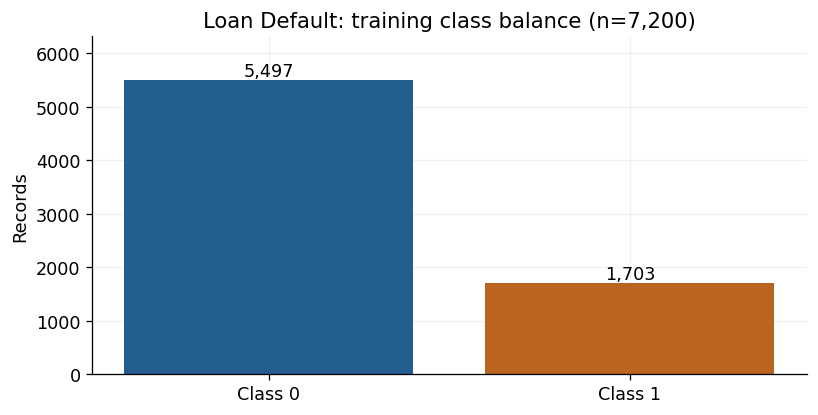

In [4]:
plot_label={'Loan_Default.csv':'Loan Default','accepted_2007_to_2018Q4.csv':'LendingClub','bank_customers.csv':'Bank customers'}[dataset_name]
train_index, valid_index, test_index, dev_index, folds = extra_split(X, y, groups, classification=True)
X_train, X_valid, X_test = [X.iloc[i] for i in [train_index, valid_index, test_index]]
y_train, y_valid, y_test = [y.iloc[i] for i in [train_index, valid_index, test_index]]
assert not (set(train_index)&set(valid_index) or set(train_index)&set(test_index) or set(valid_index)&set(test_index))
split_table = pd.DataFrame([{'Partition':label, 'Records':len(idx),
    'Class 0':int((y.iloc[idx]==0).sum()), 'Class 1':int(y.iloc[idx].sum()),
    'Positive share':y.iloc[idx].mean(),
    'Groups':len(idx) if groups is None else groups.iloc[idx].nunique()}
    for label,idx in [('Train',train_index),('Validation',valid_index),('Test',test_index)]])
display(split_table.set_index('Partition'))
display(X_train.isna().mean().mul(100).rename('Training missing (%)').to_frame())
display(X_train[numeric].agg(['min','median','max']))
fig,ax=plt.subplots(figsize=(7,3.5),layout='constrained')
counts=y_train.value_counts().reindex([0,1],fill_value=0)
ax.bar(['Class 0','Class 1'], counts, color=[BLUE,ORANGE])
for j,v in enumerate(counts): ax.text(j,v,f'{v:,}',ha='center',va='bottom')
ax.set(title=f'{plot_label}: training class balance (n={len(y_train):,})',ylabel='Records',ylim=(0,counts.max()*1.15))
plt.show()

### Audit status-linked missingness

The following training-only check demonstrates why seemingly predictive fields are excluded. It is not a candidate model.

In [5]:
audit_fields=['rate_of_interest','Interest_rate_spread','Upfront_charges','property_value','LTV','dtir1']
training_source=source_frame.loc[X_train.index]
audit=training_source.groupby('Status')[audit_fields].agg(lambda s:s.isna().mean()).T
audit.columns=['Missing share, class 0','Missing share, class 1']
display(audit)
artifact_accuracy=accuracy_score(y_train,training_source['rate_of_interest'].isna().astype(int))
display(Markdown(f'**Training-only audit:** the missing-interest-rate rule has {artifact_accuracy:.2%} accuracy. '
    'Pricing, property/LTV/DTI fields, credit_type, and post-outcome fields stay outside all models. '
    'This restricted task classifies recorded status; its undocumented timing prevents a future-default claim.'))

,"Missing share, class 0","Missing share, class 1"
rate_of_interest,0.0000,0.9941
Interest_rate_spread,0.0000,1.0000
Upfront_charges,0.0331,0.9953
property_value,0.0000,0.4116
LTV,0.0000,0.4116
dtir1,0.0773,0.4422


**Training-only audit:** the missing-interest-rate rule has 99.86% accuracy. Pricing, property/LTV/DTI fields, credit_type, and post-outcome fields stay outside all models. This restricted task classifies recorded status; its undocumented timing prevents a future-default claim.

### A3. Tune each model family on training folds

The independent validation set selects among tuned families; test outcomes do not enter selection.

In [6]:
specifications = {
    'Linear SVM': (SVC(kernel='linear', cache_size=512), {'model__C':[0.01,0.1,1]}),
    'RBF SVM': (SVC(kernel='rbf', cache_size=512),
                {'model__C':[0.1,1,10], 'model__gamma':['scale',0.01]}),
    'Polynomial SVM': (SVC(kernel='poly', degree=2, coef0=1, cache_size=512),
                       {'model__C':[0.01,0.1,1]})}
searches={}; rows=[]
for name,(model,grid) in specifications.items():
    searches[name],row=tune(model,grid)
    rows.append({'Model':name,**row})
comparison=pd.DataFrame(rows).set_index('Model')
fitted={name:search.best_estimator_ for name,search in searches.items()}
chosen_name=comparison['Validation AUC'].idxmax() # fixed insertion order breaks ties
selected=fitted[chosen_name]
display(comparison.drop(columns='Parameters'))
display(pd.DataFrame([{'Model':name,'Parameter':key.removeprefix('model__'),'Value':str(value)}
    for name,search in searches.items() for key,value in search.best_params_.items()]))
display(Markdown(f'Validation selected **{chosen_name}**. CV standard deviations describe fold variation, '
    'not confidence intervals. A bounded grid is a teaching experiment, not an exhaustive optimum.'))

,CV AUC,CV AUC SD,Train AUC,Validation AUC,Validation AP,Fit seconds
Model,,,,,,
Linear SVM,0.5071,0.0014,0.4940,0.4767,0.2381,2.1705
RBF SVM,0.5926,0.0144,0.6493,0.6209,0.3903,13.2187
Polynomial SVM,0.5666,0.0328,0.5606,0.5340,0.2748,4.1057


,Model,Parameter,Value
0,Linear SVM,C,1
1,RBF SVM,C,0.1
2,RBF SVM,gamma,scale
3,Polynomial SVM,C,1


Validation selected **RBF SVM**. CV standard deviations describe fold variation, not confidence intervals. A bounded grid is a teaching experiment, not an exhaustive optimum.

### A4. Inspect regularization and complexity

Fold-to-fold variation is descriptive, not an independent-experiment confidence interval.

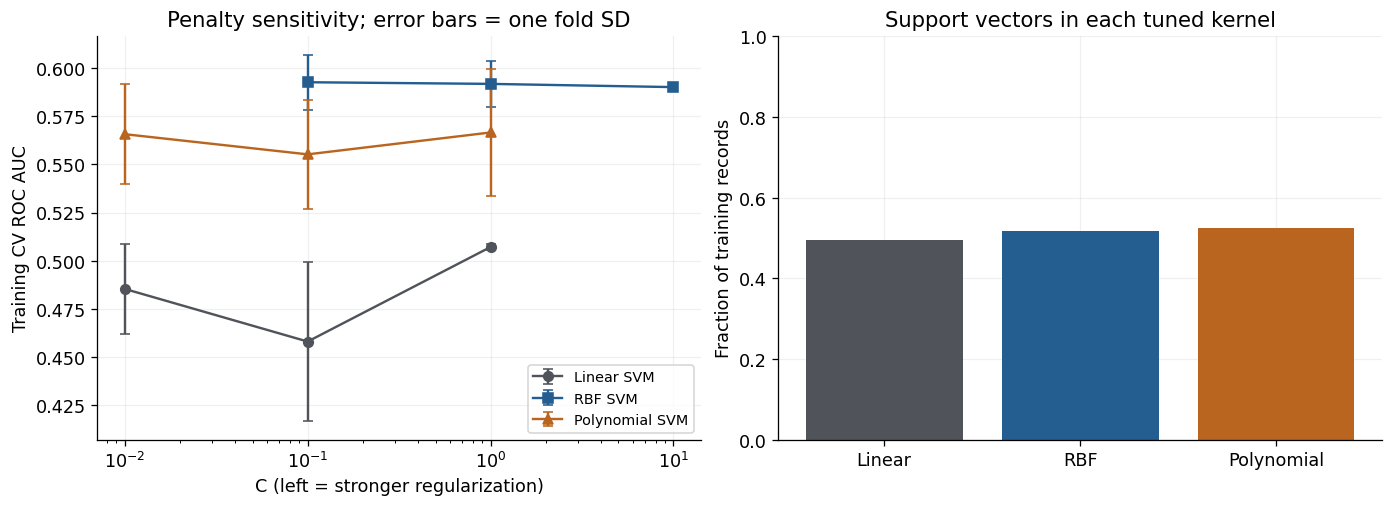

,Model,C,Support class 0,Support class 1
0,Linear SVM,1.0000,1858,1703
1,RBF SVM,0.1000,2019,1703
2,Polynomial SVM,1.0000,2080,1703


In [7]:
fig,axes=plt.subplots(1,2,figsize=(12,4.3),layout='constrained')
for name,color,marker in [('Linear SVM',GRAY,'o'),('RBF SVM',BLUE,'s'),('Polynomial SVM',ORANGE,'^')]:
    cv=pd.DataFrame(searches[name].cv_results_)
    if name=='RBF SVM': cv=cv[cv['param_model__gamma'].eq('scale')]
    cv=cv.sort_values('param_model__C')
    axes[0].errorbar(cv['param_model__C'].astype(float),cv['mean_test_auc'],
        yerr=cv['std_test_auc'],marker=marker,color=color,label=name,capsize=3)
    support=fitted[name].named_steps['model'].n_support_
    axes[1].bar(name.replace(' SVM',''),support.sum()/len(y_train),color=color)
axes[0].set(xscale='log',xlabel='C (left = stronger regularization)',ylabel='Training CV ROC AUC',
    title='Penalty sensitivity; error bars = one fold SD')
axes[0].legend(fontsize=9)
axes[1].set(ylim=(0,1),ylabel='Fraction of training records',title='Support vectors in each tuned kernel')
plt.show()
display(pd.DataFrame([{'Model':name,'C':m.named_steps['model'].C,
    'Support class 0':m.named_steps['model'].n_support_[0],
    'Support class 1':m.named_steps['model'].n_support_[1]} for name,m in fitted.items()]))

### A5. Visualize the kernel trick on this dataset

These auxiliary two-feature classifiers use fixed settings and training data only. Their plots illustrate geometry, not the tuned full-feature model’s performance. Points outside the central view remain in fitting.

Balanced class penalties make both classes visible in this geometric illustration. This fixed illustrative setting is distinct from the original unweighted model-selection experiment and from the later tuned balanced sensitivity check.

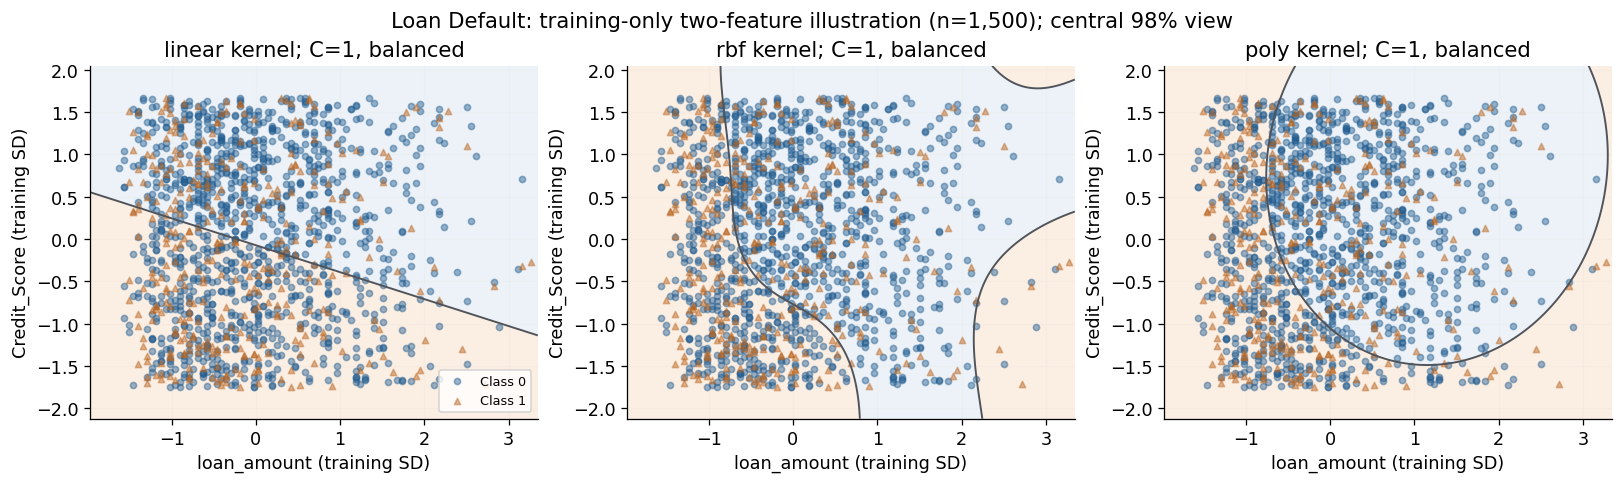

In [8]:
# Ancillary two-feature illustration uses only training data and fixed C=1.
# It is distinct from the tuned full-feature models and supplies no test metric.
plot_features = (['fico_mid','dti'] if 'fico_mid' in numeric else
                 ['loan_amount','Credit_Score'] if 'Credit_Score' in numeric else numeric[:2])
plot_X=X_train[plot_features]
if len(plot_X)>1500: plot_X=plot_X.sample(1500,random_state=SEED)
plot_y=y_train.loc[plot_X.index]
plot_prepare=Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())])
Z=plot_prepare.fit_transform(plot_X)
lo,hi=np.quantile(Z,[0.01,0.99],axis=0)
pad=np.maximum((hi-lo)*0.12,0.2); lo-=pad; hi+=pad
xx,yy=np.meshgrid(np.linspace(lo[0],hi[0],120),np.linspace(lo[1],hi[1],120))
grid=np.c_[xx.ravel(),yy.ravel()]
fig,axes=plt.subplots(1,3,figsize=(14,4.1),layout='constrained')
for ax,kernel in zip(axes,['linear','rbf','poly']):
    demo=SVC(kernel=kernel,C=1,degree=2,coef0=1,class_weight='balanced').fit(Z,plot_y)
    zz=demo.decision_function(grid).reshape(xx.shape)
    ax.contourf(xx,yy,zz,levels=[-np.inf,0,np.inf],colors=['#E8EFF5','#FAEADD'],alpha=0.8)
    if zz.min()<0<zz.max(): ax.contour(xx,yy,zz,levels=[0],colors=GRAY,linewidths=1.2)
    for label,color,marker in [(0,BLUE,'o'),(1,ORANGE,'^')]:
        mask=plot_y.to_numpy()==label
        ax.scatter(Z[mask,0],Z[mask,1],c=color,marker=marker,s=15,alpha=0.45,label=f'Class {label}')
    ax.set(xlim=(lo[0],hi[0]),ylim=(lo[1],hi[1]),title=f'{kernel} kernel; C=1, balanced',
        xlabel=plot_features[0]+' (training SD)',ylabel=plot_features[1]+' (training SD)')
axes[0].legend(fontsize=8)
fig.suptitle(f'{plot_label}: training-only two-feature illustration (n={len(Z):,}); central 98% view')
plt.show()

### Choose a validation operating rule

Search validation-score quantiles for F1. A greater cutoff breaks F1 ties. This teaching objective is not a specified business cost function.

The plot zooms to the observed validation-score range so nearly constant margins remain visible. The conventional cutoff is still assessed in the table even when it lies outside that range.

,ROC AUC,Average precision,Accuracy,Balanced accuracy,Precision,Recall,F1,Predicted positive
Rule,,,,,,,,
Default,0.6209,0.3903,0.7633,0.5000,0.0000,0.0000,0.0000,0
Validation F1,0.6209,0.3903,0.6592,0.6037,0.3468,0.4982,0.4090,816


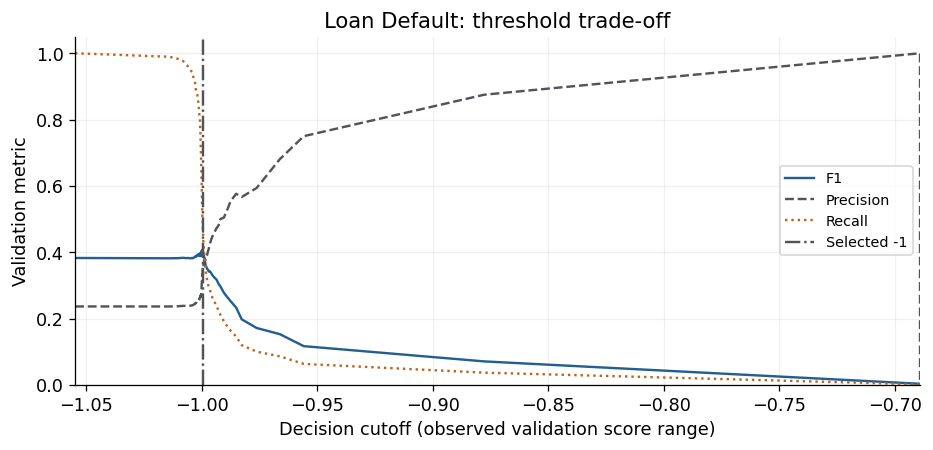

In [9]:
# Select an operating rule on validation only. Include the conventional model cutoff.
validation_scores=score_values(selected,X_valid)
default_cutoff=0.0 if hasattr(selected,'decision_function') else 0.5
cutoffs=np.unique(np.r_[np.quantile(validation_scores,np.linspace(0,1,101)),default_cutoff,
    np.nextafter(validation_scores.max(),np.inf)])
threshold_table=pd.DataFrame([{'Cutoff':t,'F1':f1_score(y_valid,validation_scores>=t,zero_division=0),
    'Precision':precision_score(y_valid,validation_scores>=t,zero_division=0),
    'Recall':recall_score(y_valid,validation_scores>=t,zero_division=0)} for t in cutoffs])
# F1 ties use the greatest cutoff, a prespecified conservative tie rule.
best=threshold_table.sort_values(['F1','Cutoff'],ascending=[False,False]).iloc[0]
chosen_cutoff=float(best['Cutoff'])
display(pd.DataFrame([{'Rule':'Default',**metrics(y_valid,validation_scores,validation_scores>=default_cutoff)},
    {'Rule':'Validation F1',**metrics(y_valid,validation_scores,validation_scores>=chosen_cutoff)}]).set_index('Rule'))
fig,ax=plt.subplots(figsize=(8,3.8),layout='constrained')
for metric,color,style in [('F1',BLUE,'-'),('Precision',GRAY,'--'),('Recall',ORANGE,':')]:
    ax.plot(threshold_table['Cutoff'],threshold_table[metric],label=metric,color=color,linestyle=style)
ax.axvline(chosen_cutoff,color=GRAY,linestyle='-.',label=f'Selected {chosen_cutoff:.3g}')
ax.set(xlabel='Decision cutoff (model score units)',ylabel='Validation metric',ylim=(0,1.05),
    title=f'{plot_label}: threshold trade-off')
ax.set_xlim(float(validation_scores.min()),float(validation_scores.max()))
ax.ticklabel_format(axis='x',style='plain',useOffset=False)
ax.set_xlabel('Decision cutoff (observed validation score range)')
ax.legend(fontsize=9);plt.show()

### Results: evaluate the frozen models once

All candidate families were declared in advance. Test rows report evidence, not a second opportunity to select a family. Default-cutoff rows and the selected validation-cutoff row distinguish ranking from decision quality.

In [10]:
# Freeze training-fitted estimators: no refit, so the selected score cutoff stays on its original scale.
logistic=pipeline(LogisticRegression(C=1,max_iter=10000)).fit(X_train,y_train)
dummy=DummyClassifier(strategy='prior').fit(X_train,y_train)
test_models={**fitted,'Logistic baseline':logistic,'Prevalence baseline':dummy}
test_rows=[]
for name,model in test_models.items():
    scores=score_values(model,X_test)
    prediction=model.predict(X_test)
    test_rows.append({'Model':name,**metrics(y_test,scores,prediction)})
test_scores=score_values(selected,X_test)
test_prediction=test_scores>=chosen_cutoff
test_rows.append({'Model':chosen_name+' (validation F1 cutoff)',**metrics(y_test,test_scores,test_prediction)})
test_table=pd.DataFrame(test_rows).set_index('Model')
display(test_table)
# Assertions independently reconcile the selected confusion counts and rank metric.
cm=confusion_matrix(y_test,test_prediction,labels=[0,1])
assert cm.sum()==len(y_test) and cm[1].sum()==y_test.sum()
assert np.isclose(roc_auc_score(y_test,test_scores),test_table.loc[chosen_name,'ROC AUC'])
# Stratified row bootstrap: descriptive conditional uncertainty for the two loan samples only.
# Bank rows have grouped dependence and too few held-out accounts for a useful interval.
auc_interval=None
if groups is None:
    rng_ci=np.random.default_rng(SEED)
    yy_test=y_test.to_numpy(); neg=np.flatnonzero(yy_test==0); pos=np.flatnonzero(yy_test==1)
    draws=[]
    for _ in range(300):
        idx=np.r_[rng_ci.choice(neg,len(neg),replace=True),rng_ci.choice(pos,len(pos),replace=True)]
        draws.append(roc_auc_score(yy_test[idx],test_scores[idx]))
    auc_interval=np.quantile(draws,[0.025,0.975])
    print(f'95% stratified row-bootstrap AUC interval: [{auc_interval[0]:.3f}, {auc_interval[1]:.3f}]')
    print('Conditional on the fitted model, fixed class counts and row independence; excludes selection/training uncertainty.')
else:
    print('Bank test set: exact confusion counts are primary; no reliable population interval is claimed.')
results.append({'Dataset':dataset_name,'Outcome':outcome_label,'Selected':chosen_name,
    'Train n':len(y_train),'Validation n':len(y_valid),'Test n':len(y_test),
    'ROC AUC':roc_auc_score(y_test,test_scores),'Average precision':average_precision_score(y_test,test_scores),
    'Test positive share':y_test.mean(),'F1 (validation cutoff)':f1_score(y_test,test_prediction,zero_division=0),
    'Cutoff':chosen_cutoff})

,ROC AUC,Average precision,Accuracy,Balanced accuracy,Precision,Recall,F1,Predicted positive
Model,,,,,,,,
Linear SVM,0.4822,0.2398,0.7633,0.5000,0.0000,0.0000,0.0000,0
RBF SVM,0.5900,0.3510,0.7633,0.5000,0.0000,0.0000,0.0000,0
Polynomial SVM,0.5420,0.2922,0.7633,0.5000,0.0000,0.0000,0.0000,0
Logistic baseline,0.5906,0.2968,0.7633,0.5000,0.0000,0.0000,0.0000,0
Prevalence baseline,0.5000,0.2367,0.7633,0.5000,0.0000,0.0000,0.0000,0
RBF SVM (validation F1 cutoff),0.5900,0.3510,0.6646,0.5793,0.3333,0.4173,0.3706,711


95% stratified row-bootstrap AUC interval: [0.563, 0.618]
Conditional on the fitted model, fixed class counts and row independence; excludes selection/training uncertainty.


### Inspect held-out ranking and errors

The precision–recall baseline is this test partition’s positive share. Confusion counts use the frozen validation F1 cutoff.

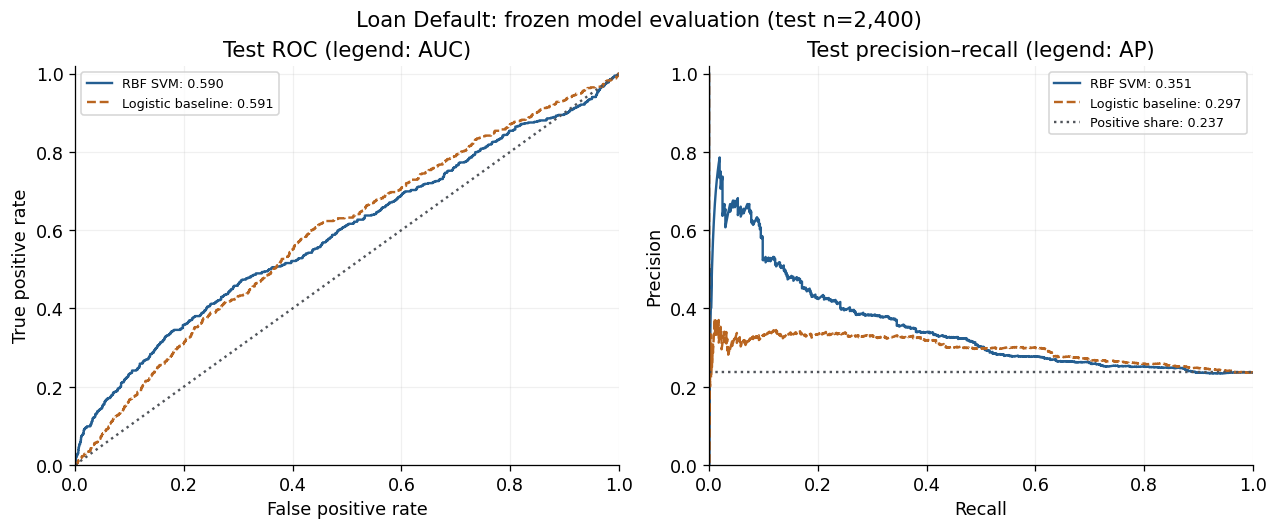

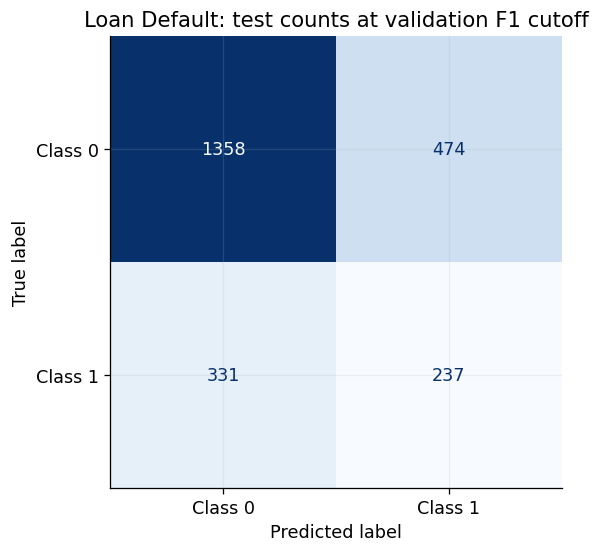

In [11]:
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
for name,model,color,style in [(chosen_name,selected,BLUE,'-'),('Logistic baseline',logistic,ORANGE,'--')]:
    scores=score_values(model,X_test)
    fpr,tpr,_=roc_curve(y_test,scores)
    precision,recall,_=precision_recall_curve(y_test,scores)
    axes[0].plot(fpr,tpr,color=color,linestyle=style,label=f'{name}: {roc_auc_score(y_test,scores):.3f}')
    axes[1].plot(recall,precision,color=color,linestyle=style,label=f'{name}: {average_precision_score(y_test,scores):.3f}')
axes[0].plot([0,1],[0,1],color=GRAY,linestyle=':')
axes[1].axhline(y_test.mean(),color=GRAY,linestyle=':',label=f'Positive share: {y_test.mean():.3f}')
axes[0].set(title='Test ROC (legend: AUC)',xlabel='False positive rate',ylabel='True positive rate',xlim=(0,1),ylim=(0,1.02))
axes[1].set(title='Test precision–recall (legend: AP)',xlabel='Recall',ylabel='Precision',xlim=(0,1),ylim=(0,1.02))
axes[0].legend(fontsize=8);axes[1].legend(fontsize=8)
fig.suptitle(f'{plot_label}: frozen model evaluation (test n={len(y_test):,})')
plt.show()
fig,ax=plt.subplots(figsize=(5.5,4.7),layout='constrained')
ConfusionMatrixDisplay(cm,display_labels=['Class 0','Class 1']).plot(ax=ax,colorbar=False,cmap='Blues')
ax.set_title(f'{plot_label}: test counts at validation F1 cutoff')
plt.show()

In [12]:
r=results[-1]
log_auc=test_table.loc['Logistic baseline','ROC AUC']
sv_note = (f"The selected kernel uses C={selected.named_steps['model'].C}; "
    f"{selected.named_steps['model'].n_support_.sum():,}/{len(y_train):,} training records are support vectors. "
    "The kernel comparison and CV penalty path show whether extra flexibility helped within this finite search."
    if hasattr(selected.named_steps['model'],'n_support_') else
    "The unrestricted-tree comparison exposes training optimism; CV complexity curves and held-out forest importance "
    "make the depth/variance trade-off inspectable. A forest is not guaranteed to beat a tuned single tree.")
caveat = ('Only eight bank test records support this estimate. One changed label or prediction can materially change it; '
    'checking status is an account attribute, not a credit-risk outcome.' if groups is not None else
    'These historical random-split results do not establish future-cohort accuracy or borrower independence. '
    'The loan outcome definitions and exclusions limit the population to which this result applies.')
display(Markdown(f'''### Dataset takeaways — {dataset_name}

Validation selected **{chosen_name}**; the frozen model has test ROC AUC **{r['ROC AUC']:.3f}** and average precision **{r['Average precision']:.3f}**, against test positive share **{r['Test positive share']:.3f}**. The prespecified logistic baseline has AUC **{log_auc:.3f}** (descriptive difference **{r['ROC AUC']-log_auc:+.3f}**, not a significance claim).

{sv_note}

The validation-selected operating rule yields test F1 **{r['F1 (validation cutoff)']:.3f}** and confusion counts TN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]}. F1 weights precision and recall equally and ignores true negatives; a deployed cutoff would require explicit costs. Validation F1 is optimistic because it selected this cutoff.

{caveat} These are associations. No causal, fairness, calibrated-risk or deployment claim is supported.
'''))

### Dataset takeaways — Loan_Default.csv

Validation selected **RBF SVM**; the frozen model has test ROC AUC **0.590** and average precision **0.351**, against test positive share **0.237**. The prespecified logistic baseline has AUC **0.591** (descriptive difference **-0.001**, not a significance claim).

The selected kernel uses C=0.1; 3,722/7,200 training records are support vectors. The kernel comparison and CV penalty path show whether extra flexibility helped within this finite search.

The validation-selected operating rule yields test F1 **0.371** and confusion counts TN=1358, FP=474, FN=331, TP=237. F1 weights precision and recall equally and ignores true negatives; a deployed cutoff would require explicit costs. Validation F1 is optimistic because it selected this cutoff.

These historical random-split results do not establish future-cohort accuracy or borrower independence. The loan outcome definitions and exclusions limit the population to which this result applies. These are associations. No causal, fairness, calibrated-risk or deployment claim is supported.


**What this dataset teaches.** The selected unweighted RBF model's test AUC (0.590) is effectively the same as the fixed logistic baseline (0.591) in this run. Nonlinearity alone did not improve the restricted task. The exploratory balanced-linear check improved **validation** AUC by 0.120, suggesting that the penalty assigned to each class deserves further study on a fresh holdout.

### Exploratory follow-up: class-specific margin penalties

The first completed run showed weak SVM ranking and majority-class decisions on the imbalanced lending sample. This follow-up checks one possible explanation on **training and validation only**. `class_weight='balanced'` replaces the common C by class-specific $C_k=C\,n/(2n_k)$, computed from each fitting fold. This increases the penalty for minority-class violations; it does not change the observed class prevalence or create probabilities.

Tune the balanced **linear** SVM on the original training folds and compare its validation ranking with the original linear model. This was added after the original run was inspected: it is exploratory, **does not replace the selected family or cutoff**, and receives **no additional test evaluation**. A fresh future holdout would be needed before promoting it as an improvement.

In [13]:
balanced_search, balanced_row=tune(SVC(kernel='linear',class_weight='balanced',cache_size=512),
    {'model__C':[0.01,0.1,1]})
sensitivity=pd.DataFrame([
    {'Linear penalty':'Unweighted',**comparison.loc['Linear SVM'].to_dict()},
    {'Linear penalty':'Balanced (exploratory)',**balanced_row}]).set_index('Linear penalty')
display(sensitivity[['CV AUC','CV AUC SD','Validation AUC','Validation AP','Parameters']])
margin=score_values(fitted['Linear SVM'],X_valid)
balanced_margin=score_values(balanced_search.best_estimator_,X_valid)
display(pd.DataFrame([
    {'Linear penalty':'Unweighted', 'Validation positives at margin 0':int((margin>=0).sum()),
     'Validation score SD':float(np.std(margin))},
    {'Linear penalty':'Balanced (exploratory)', 'Validation positives at margin 0':int((balanced_margin>=0).sum()),
     'Validation score SD':float(np.std(balanced_margin))}]).set_index('Linear penalty'))
delta=balanced_row['Validation AUC']-comparison.loc['Linear SVM','Validation AUC']
display(Markdown(f'Balanced penalties change validation AUC by **{delta:+.3f}** relative to the original linear SVM. '
    'Near-constant scores or very few positive decisions can occur when hinge loss favors a majority-class rule. '
    'This check does not establish the cause of every weak kernel result or validate a new final model.'))

,CV AUC,CV AUC SD,Validation AUC,Validation AP,Parameters
Linear penalty,,,,,
Unweighted,0.5071,0.0014,0.4767,0.2381,{'model__C': 1}
Balanced (exploratory),0.5862,0.0123,0.5971,0.3152,{'model__C': 0.01}


,Validation positives at margin 0,Validation score SD
Linear penalty,,
Unweighted,0,0.0001
Balanced (exploratory),698,0.6848


Balanced penalties change validation AUC by **+0.120** relative to the original linear SVM. Near-constant scores or very few positive decisions can occur when hinge loss favors a majority-class rule. This check does not establish the cause of every weak kernel result or validate a new final model.

## B. accepted_2007_to_2018Q4.csv — independent analysis

**Outcome:** Charged Off=1 versus Fully Paid=0, conditional on **resolved 2015 36-month loans**. Stream the entire 1.6 GB file and retain a uniform random-priority sample of 12,000 eligible loans. Count all source rows, cohort exclusions and unresolved/other statuses. Use application-era amount, income, FICO, DTI, revolving utilization, open accounts, home ownership, purpose and verification status. Exclude repayments, recoveries, current status, grade and pricing from predictors. No unknown or ongoing loan is labeled fully paid. Historical resolved-only selection and incomplete feature-timing documentation limit prospective interpretation.

### B1. Load and reconcile source data

In [14]:
dataset_name = 'accepted_2007_to_2018Q4.csv'
outcome_label = 'charged off among resolved 2015 36-month loans'
USECOLS = ['id', 'loan_amnt', 'annual_inc', 'fico_range_low', 'fico_range_high',
           'dti', 'revol_util', 'open_acc', 'emp_length', 'earliest_cr_line',
           'issue_d', 'loan_status', 'term', 'home_ownership', 'purpose', 'verification_status']
rng = np.random.default_rng(SEED)
frame = pd.DataFrame()
all_rows = vintage_rows = short_term_rows = eligible_rows = 0
status_counts = pd.Series(dtype='int64')
for chunk in pd.read_csv(DATA_DIR / dataset_name, usecols=USECOLS, chunksize=150_000, low_memory=False):
    all_rows += len(chunk)
    cohort = chunk.loc[chunk['issue_d'].astype('str').str.endswith('2015')].copy()
    vintage_rows += len(cohort)
    cohort = cohort.loc[cohort['term'].str.strip().eq('36 months')]
    short_term_rows += len(cohort)
    status_counts = status_counts.add(cohort['loan_status'].value_counts(), fill_value=0)
    cohort = cohort.loc[cohort['loan_status'].isin(['Fully Paid', 'Charged Off'])].copy()
    eligible_rows += len(cohort)
    if len(cohort):
        cohort['_priority'] = rng.random(len(cohort))
        frame = pd.concat([frame, cohort.nsmallest(SAMPLE_SIZE, '_priority')]).nsmallest(SAMPLE_SIZE, '_priority')
frame = frame.drop(columns='_priority').reset_index(drop=True)
assert frame['id'].notna().all() and frame['id'].is_unique
display(pd.Series({'source rows': all_rows, '2015 records': vintage_rows,
    '2015 36-month records': short_term_rows, 'resolved eligible records': eligible_rows,
    'excluded unresolved/other statuses': short_term_rows - eligible_rows,
    'uniform sample': len(frame)}, name='Resolved-outcome cohort'))
display(status_counts.astype(int).rename('2015 36-month records').to_frame())
X = pd.DataFrame({
    'log_loan_amount': np.log1p(frame['loan_amnt'].where(frame['loan_amnt'] > 0)),
    'log_annual_income': np.log1p(frame['annual_inc'].where(frame['annual_inc'] >= 0)),
    'fico_mid': (frame['fico_range_low'] + frame['fico_range_high']) / 2,
    'dti': frame['dti'].where(frame['dti'] >= 0),
    'revol_util': frame['revol_util'].where(frame['revol_util'] >= 0),
    'open_acc': frame['open_acc']})
numeric = list(X.columns)
categorical = ['home_ownership', 'purpose', 'verification_status']
for name in categorical:
    X[name] = frame[name].astype(object).where(frame[name].notna(), np.nan)
y = frame['loan_status'].eq('Charged Off').astype(int)
groups = None

source rows                           2260701
2015 records                           421095
2015 36-month records                  283173
resolved eligible records              283026
excluded unresolved/other statuses        147
uniform sample                          12000
Name: Resolved-outcome cohort, dtype: int64

,2015 36-month records
loan_status,
Charged Off,42132
Current,72
Fully Paid,240894
In Grace Period,9
Late (16-30 days),5
Late (31-120 days),61


### B2. Reserve evaluation records and audit training inputs

Only fixed row-wise feature rules precede splitting. Class counts are shown for every partition; learned imputation, encoding and scaling remain within training folds.

,Records,Class 0,Class 1,Positive share,Groups
Partition,,,,,
Train,7200,6193,1007,0.1399,7200
Validation,2400,2064,336,0.1400,2400
Test,2400,2064,336,0.1400,2400


,Training missing (%)
log_loan_amount,0.0000
log_annual_income,0.0000
fico_mid,0.0000
dti,0.0000
revol_util,0.0278
open_acc,0.0000
home_ownership,0.0000
purpose,0.0000
verification_status,0.0000


,log_loan_amount,log_annual_income,fico_mid,dti,revol_util,open_acc
min,6.9088,8.6997,662.0000,0.1000,0.0000,2.0000
median,9.2104,11.0420,687.0000,17.9400,52.3000,11.0000
max,10.4631,14.4033,847.5000,39.9600,132.5000,47.0000


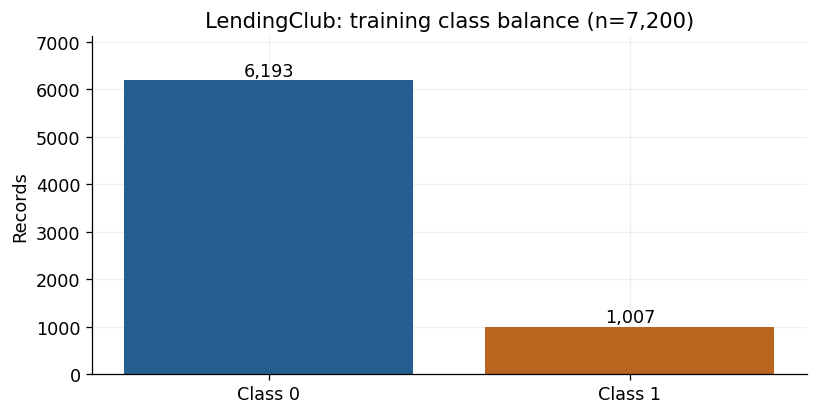

In [15]:
plot_label={'Loan_Default.csv':'Loan Default','accepted_2007_to_2018Q4.csv':'LendingClub','bank_customers.csv':'Bank customers'}[dataset_name]
train_index, valid_index, test_index, dev_index, folds = extra_split(X, y, groups, classification=True)
X_train, X_valid, X_test = [X.iloc[i] for i in [train_index, valid_index, test_index]]
y_train, y_valid, y_test = [y.iloc[i] for i in [train_index, valid_index, test_index]]
assert not (set(train_index)&set(valid_index) or set(train_index)&set(test_index) or set(valid_index)&set(test_index))
split_table = pd.DataFrame([{'Partition':label, 'Records':len(idx),
    'Class 0':int((y.iloc[idx]==0).sum()), 'Class 1':int(y.iloc[idx].sum()),
    'Positive share':y.iloc[idx].mean(),
    'Groups':len(idx) if groups is None else groups.iloc[idx].nunique()}
    for label,idx in [('Train',train_index),('Validation',valid_index),('Test',test_index)]])
display(split_table.set_index('Partition'))
display(X_train.isna().mean().mul(100).rename('Training missing (%)').to_frame())
display(X_train[numeric].agg(['min','median','max']))
fig,ax=plt.subplots(figsize=(7,3.5),layout='constrained')
counts=y_train.value_counts().reindex([0,1],fill_value=0)
ax.bar(['Class 0','Class 1'], counts, color=[BLUE,ORANGE])
for j,v in enumerate(counts): ax.text(j,v,f'{v:,}',ha='center',va='bottom')
ax.set(title=f'{plot_label}: training class balance (n={len(y_train):,})',ylabel='Records',ylim=(0,counts.max()*1.15))
plt.show()

### B3. Tune each model family on training folds

The independent validation set selects among tuned families; test outcomes do not enter selection.

In [16]:
specifications = {
    'Linear SVM': (SVC(kernel='linear', cache_size=512), {'model__C':[0.01,0.1,1]}),
    'RBF SVM': (SVC(kernel='rbf', cache_size=512),
                {'model__C':[0.1,1,10], 'model__gamma':['scale',0.01]}),
    'Polynomial SVM': (SVC(kernel='poly', degree=2, coef0=1, cache_size=512),
                       {'model__C':[0.01,0.1,1]})}
searches={}; rows=[]
for name,(model,grid) in specifications.items():
    searches[name],row=tune(model,grid)
    rows.append({'Model':name,**row})
comparison=pd.DataFrame(rows).set_index('Model')
fitted={name:search.best_estimator_ for name,search in searches.items()}
chosen_name=comparison['Validation AUC'].idxmax() # fixed insertion order breaks ties
selected=fitted[chosen_name]
display(comparison.drop(columns='Parameters'))
display(pd.DataFrame([{'Model':name,'Parameter':key.removeprefix('model__'),'Value':str(value)}
    for name,search in searches.items() for key,value in search.best_params_.items()]))
display(Markdown(f'Validation selected **{chosen_name}**. CV standard deviations describe fold variation, '
    'not confidence intervals. A bounded grid is a teaching experiment, not an exhaustive optimum.'))

,CV AUC,CV AUC SD,Train AUC,Validation AUC,Validation AP,Fit seconds
Model,,,,,,
Linear SVM,0.5160,0.0611,0.5694,0.5254,0.1617,1.6007
RBF SVM,0.5503,0.0058,0.8566,0.5252,0.1611,12.0109
Polynomial SVM,0.5249,0.0301,0.5186,0.4548,0.1366,2.4908


,Model,Parameter,Value
0,Linear SVM,C,0.1
1,RBF SVM,C,10
2,RBF SVM,gamma,scale
3,Polynomial SVM,C,0.1


Validation selected **Linear SVM**. CV standard deviations describe fold variation, not confidence intervals. A bounded grid is a teaching experiment, not an exhaustive optimum.

### B4. Inspect regularization and complexity

Fold-to-fold variation is descriptive, not an independent-experiment confidence interval.

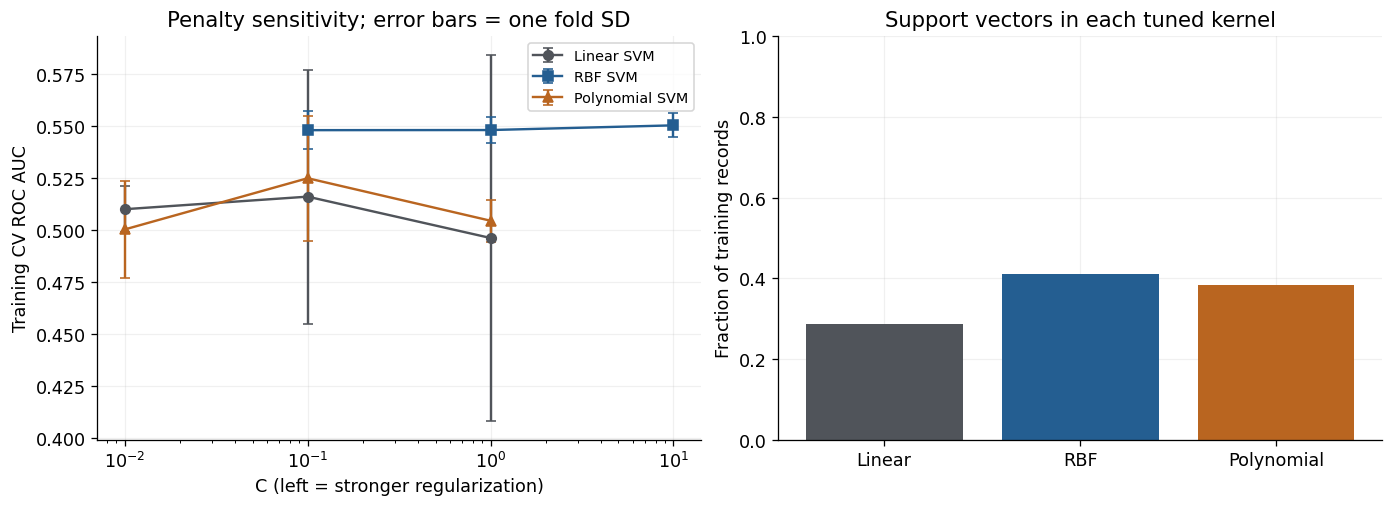

,Model,C,Support class 0,Support class 1
0,Linear SVM,0.1000,1055,1007
1,RBF SVM,10.0000,1951,1007
2,Polynomial SVM,0.1000,1758,1007


In [17]:
fig,axes=plt.subplots(1,2,figsize=(12,4.3),layout='constrained')
for name,color,marker in [('Linear SVM',GRAY,'o'),('RBF SVM',BLUE,'s'),('Polynomial SVM',ORANGE,'^')]:
    cv=pd.DataFrame(searches[name].cv_results_)
    if name=='RBF SVM': cv=cv[cv['param_model__gamma'].eq('scale')]
    cv=cv.sort_values('param_model__C')
    axes[0].errorbar(cv['param_model__C'].astype(float),cv['mean_test_auc'],
        yerr=cv['std_test_auc'],marker=marker,color=color,label=name,capsize=3)
    support=fitted[name].named_steps['model'].n_support_
    axes[1].bar(name.replace(' SVM',''),support.sum()/len(y_train),color=color)
axes[0].set(xscale='log',xlabel='C (left = stronger regularization)',ylabel='Training CV ROC AUC',
    title='Penalty sensitivity; error bars = one fold SD')
axes[0].legend(fontsize=9)
axes[1].set(ylim=(0,1),ylabel='Fraction of training records',title='Support vectors in each tuned kernel')
plt.show()
display(pd.DataFrame([{'Model':name,'C':m.named_steps['model'].C,
    'Support class 0':m.named_steps['model'].n_support_[0],
    'Support class 1':m.named_steps['model'].n_support_[1]} for name,m in fitted.items()]))

### B5. Visualize the kernel trick on this dataset

These auxiliary two-feature classifiers use fixed settings and training data only. Their plots illustrate geometry, not the tuned full-feature model’s performance. Points outside the central view remain in fitting.

Balanced class penalties make both classes visible in this geometric illustration. This fixed illustrative setting is distinct from the original unweighted model-selection experiment and from the later tuned balanced sensitivity check.

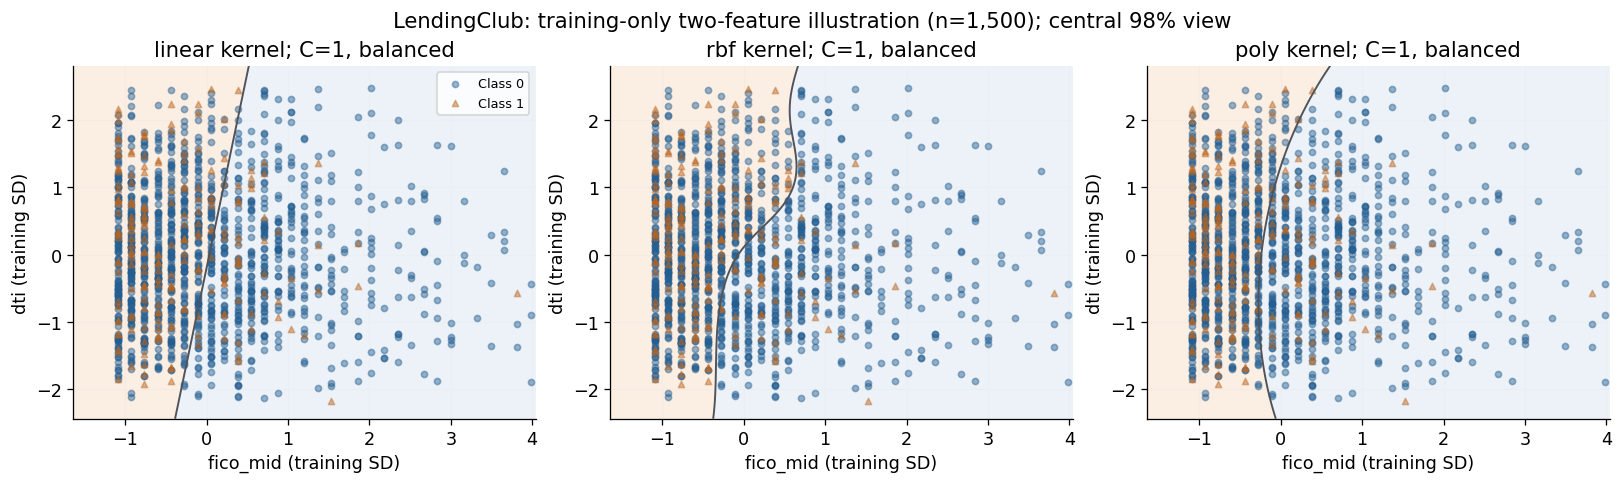

In [18]:
# Ancillary two-feature illustration uses only training data and fixed C=1.
# It is distinct from the tuned full-feature models and supplies no test metric.
plot_features = (['fico_mid','dti'] if 'fico_mid' in numeric else
                 ['loan_amount','Credit_Score'] if 'Credit_Score' in numeric else numeric[:2])
plot_X=X_train[plot_features]
if len(plot_X)>1500: plot_X=plot_X.sample(1500,random_state=SEED)
plot_y=y_train.loc[plot_X.index]
plot_prepare=Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())])
Z=plot_prepare.fit_transform(plot_X)
lo,hi=np.quantile(Z,[0.01,0.99],axis=0)
pad=np.maximum((hi-lo)*0.12,0.2); lo-=pad; hi+=pad
xx,yy=np.meshgrid(np.linspace(lo[0],hi[0],120),np.linspace(lo[1],hi[1],120))
grid=np.c_[xx.ravel(),yy.ravel()]
fig,axes=plt.subplots(1,3,figsize=(14,4.1),layout='constrained')
for ax,kernel in zip(axes,['linear','rbf','poly']):
    demo=SVC(kernel=kernel,C=1,degree=2,coef0=1,class_weight='balanced').fit(Z,plot_y)
    zz=demo.decision_function(grid).reshape(xx.shape)
    ax.contourf(xx,yy,zz,levels=[-np.inf,0,np.inf],colors=['#E8EFF5','#FAEADD'],alpha=0.8)
    if zz.min()<0<zz.max(): ax.contour(xx,yy,zz,levels=[0],colors=GRAY,linewidths=1.2)
    for label,color,marker in [(0,BLUE,'o'),(1,ORANGE,'^')]:
        mask=plot_y.to_numpy()==label
        ax.scatter(Z[mask,0],Z[mask,1],c=color,marker=marker,s=15,alpha=0.45,label=f'Class {label}')
    ax.set(xlim=(lo[0],hi[0]),ylim=(lo[1],hi[1]),title=f'{kernel} kernel; C=1, balanced',
        xlabel=plot_features[0]+' (training SD)',ylabel=plot_features[1]+' (training SD)')
axes[0].legend(fontsize=8)
fig.suptitle(f'{plot_label}: training-only two-feature illustration (n={len(Z):,}); central 98% view')
plt.show()

### Choose a validation operating rule

Search validation-score quantiles for F1. A greater cutoff breaks F1 ties. This teaching objective is not a specified business cost function.

The plot zooms to the observed validation-score range so nearly constant margins remain visible. The conventional cutoff is still assessed in the table even when it lies outside that range.

,ROC AUC,Average precision,Accuracy,Balanced accuracy,Precision,Recall,F1,Predicted positive
Rule,,,,,,,,
Default,0.5254,0.1617,0.8600,0.5000,0.0000,0.0000,0.0000,0
Validation F1,0.5254,0.1617,0.2767,0.5147,0.1443,0.8452,0.2465,1968


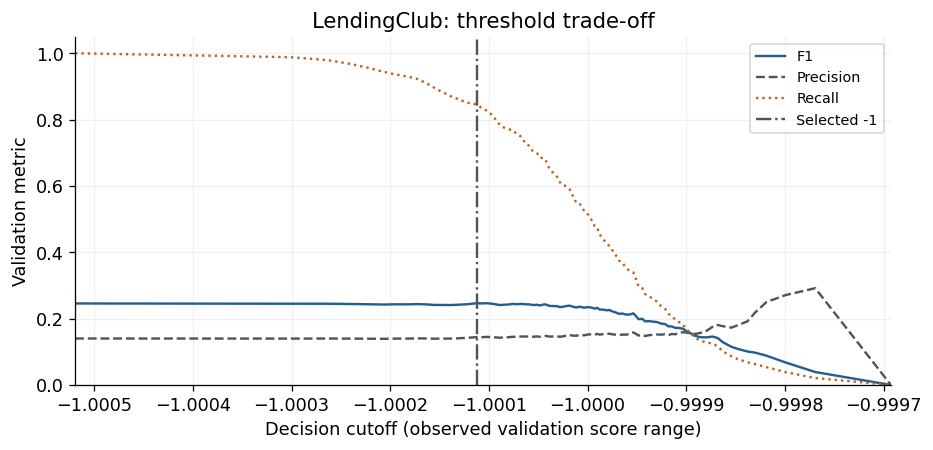

In [19]:
# Select an operating rule on validation only. Include the conventional model cutoff.
validation_scores=score_values(selected,X_valid)
default_cutoff=0.0 if hasattr(selected,'decision_function') else 0.5
cutoffs=np.unique(np.r_[np.quantile(validation_scores,np.linspace(0,1,101)),default_cutoff,
    np.nextafter(validation_scores.max(),np.inf)])
threshold_table=pd.DataFrame([{'Cutoff':t,'F1':f1_score(y_valid,validation_scores>=t,zero_division=0),
    'Precision':precision_score(y_valid,validation_scores>=t,zero_division=0),
    'Recall':recall_score(y_valid,validation_scores>=t,zero_division=0)} for t in cutoffs])
# F1 ties use the greatest cutoff, a prespecified conservative tie rule.
best=threshold_table.sort_values(['F1','Cutoff'],ascending=[False,False]).iloc[0]
chosen_cutoff=float(best['Cutoff'])
display(pd.DataFrame([{'Rule':'Default',**metrics(y_valid,validation_scores,validation_scores>=default_cutoff)},
    {'Rule':'Validation F1',**metrics(y_valid,validation_scores,validation_scores>=chosen_cutoff)}]).set_index('Rule'))
fig,ax=plt.subplots(figsize=(8,3.8),layout='constrained')
for metric,color,style in [('F1',BLUE,'-'),('Precision',GRAY,'--'),('Recall',ORANGE,':')]:
    ax.plot(threshold_table['Cutoff'],threshold_table[metric],label=metric,color=color,linestyle=style)
ax.axvline(chosen_cutoff,color=GRAY,linestyle='-.',label=f'Selected {chosen_cutoff:.3g}')
ax.set(xlabel='Decision cutoff (model score units)',ylabel='Validation metric',ylim=(0,1.05),
    title=f'{plot_label}: threshold trade-off')
ax.set_xlim(float(validation_scores.min()),float(validation_scores.max()))
ax.ticklabel_format(axis='x',style='plain',useOffset=False)
ax.set_xlabel('Decision cutoff (observed validation score range)')
ax.legend(fontsize=9);plt.show()

### Results: evaluate the frozen models once

All candidate families were declared in advance. Test rows report evidence, not a second opportunity to select a family. Default-cutoff rows and the selected validation-cutoff row distinguish ranking from decision quality.

In [20]:
# Freeze training-fitted estimators: no refit, so the selected score cutoff stays on its original scale.
logistic=pipeline(LogisticRegression(C=1,max_iter=10000)).fit(X_train,y_train)
dummy=DummyClassifier(strategy='prior').fit(X_train,y_train)
test_models={**fitted,'Logistic baseline':logistic,'Prevalence baseline':dummy}
test_rows=[]
for name,model in test_models.items():
    scores=score_values(model,X_test)
    prediction=model.predict(X_test)
    test_rows.append({'Model':name,**metrics(y_test,scores,prediction)})
test_scores=score_values(selected,X_test)
test_prediction=test_scores>=chosen_cutoff
test_rows.append({'Model':chosen_name+' (validation F1 cutoff)',**metrics(y_test,test_scores,test_prediction)})
test_table=pd.DataFrame(test_rows).set_index('Model')
display(test_table)
# Assertions independently reconcile the selected confusion counts and rank metric.
cm=confusion_matrix(y_test,test_prediction,labels=[0,1])
assert cm.sum()==len(y_test) and cm[1].sum()==y_test.sum()
assert np.isclose(roc_auc_score(y_test,test_scores),test_table.loc[chosen_name,'ROC AUC'])
# Stratified row bootstrap: descriptive conditional uncertainty for the two loan samples only.
# Bank rows have grouped dependence and too few held-out accounts for a useful interval.
auc_interval=None
if groups is None:
    rng_ci=np.random.default_rng(SEED)
    yy_test=y_test.to_numpy(); neg=np.flatnonzero(yy_test==0); pos=np.flatnonzero(yy_test==1)
    draws=[]
    for _ in range(300):
        idx=np.r_[rng_ci.choice(neg,len(neg),replace=True),rng_ci.choice(pos,len(pos),replace=True)]
        draws.append(roc_auc_score(yy_test[idx],test_scores[idx]))
    auc_interval=np.quantile(draws,[0.025,0.975])
    print(f'95% stratified row-bootstrap AUC interval: [{auc_interval[0]:.3f}, {auc_interval[1]:.3f}]')
    print('Conditional on the fitted model, fixed class counts and row independence; excludes selection/training uncertainty.')
else:
    print('Bank test set: exact confusion counts are primary; no reliable population interval is claimed.')
results.append({'Dataset':dataset_name,'Outcome':outcome_label,'Selected':chosen_name,
    'Train n':len(y_train),'Validation n':len(y_valid),'Test n':len(y_test),
    'ROC AUC':roc_auc_score(y_test,test_scores),'Average precision':average_precision_score(y_test,test_scores),
    'Test positive share':y_test.mean(),'F1 (validation cutoff)':f1_score(y_test,test_prediction,zero_division=0),
    'Cutoff':chosen_cutoff})

,ROC AUC,Average precision,Accuracy,Balanced accuracy,Precision,Recall,F1,Predicted positive
Model,,,,,,,,
Linear SVM,0.5335,0.1725,0.8600,0.5000,0.0000,0.0000,0.0000,0
RBF SVM,0.5517,0.1639,0.8525,0.4981,0.0909,0.0060,0.0112,22
Polynomial SVM,0.4908,0.1392,0.8600,0.5000,0.0000,0.0000,0.0000,0
Logistic baseline,0.6333,0.2087,0.8600,0.5000,0.0000,0.0000,0.0000,0
Prevalence baseline,0.5000,0.1400,0.8600,0.5000,0.0000,0.0000,0.0000,0
Linear SVM (validation F1 cutoff),0.5335,0.1725,0.2583,0.4990,0.1397,0.8333,0.2393,2004


95% stratified row-bootstrap AUC interval: [0.493, 0.563]
Conditional on the fitted model, fixed class counts and row independence; excludes selection/training uncertainty.


### Inspect held-out ranking and errors

The precision–recall baseline is this test partition’s positive share. Confusion counts use the frozen validation F1 cutoff.

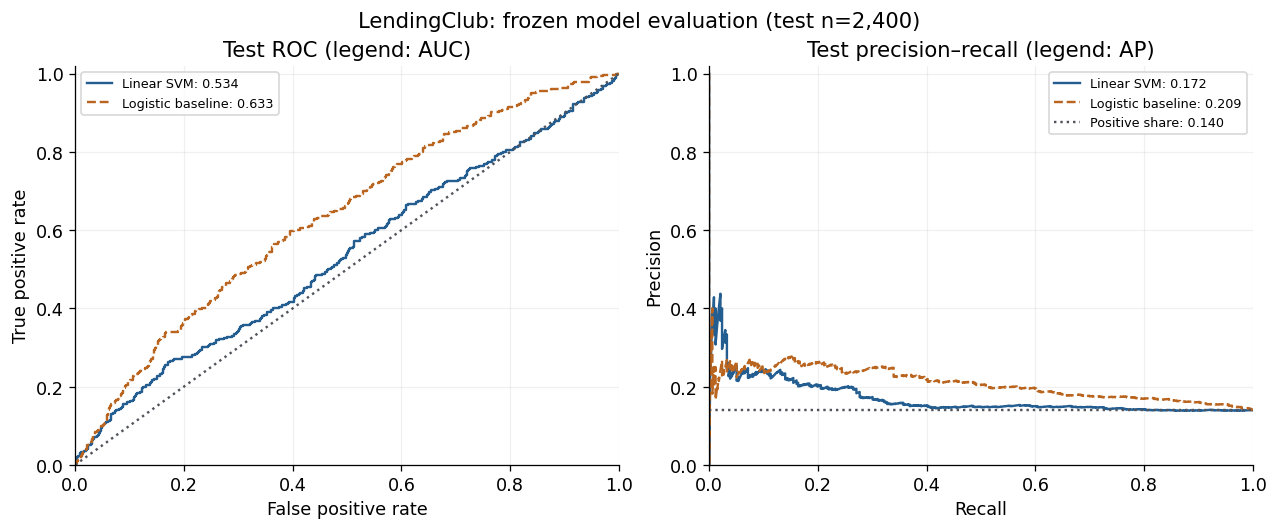

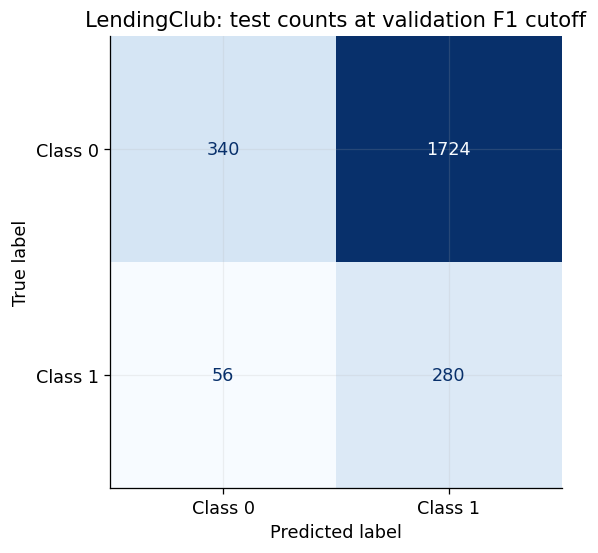

In [21]:
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
for name,model,color,style in [(chosen_name,selected,BLUE,'-'),('Logistic baseline',logistic,ORANGE,'--')]:
    scores=score_values(model,X_test)
    fpr,tpr,_=roc_curve(y_test,scores)
    precision,recall,_=precision_recall_curve(y_test,scores)
    axes[0].plot(fpr,tpr,color=color,linestyle=style,label=f'{name}: {roc_auc_score(y_test,scores):.3f}')
    axes[1].plot(recall,precision,color=color,linestyle=style,label=f'{name}: {average_precision_score(y_test,scores):.3f}')
axes[0].plot([0,1],[0,1],color=GRAY,linestyle=':')
axes[1].axhline(y_test.mean(),color=GRAY,linestyle=':',label=f'Positive share: {y_test.mean():.3f}')
axes[0].set(title='Test ROC (legend: AUC)',xlabel='False positive rate',ylabel='True positive rate',xlim=(0,1),ylim=(0,1.02))
axes[1].set(title='Test precision–recall (legend: AP)',xlabel='Recall',ylabel='Precision',xlim=(0,1),ylim=(0,1.02))
axes[0].legend(fontsize=8);axes[1].legend(fontsize=8)
fig.suptitle(f'{plot_label}: frozen model evaluation (test n={len(y_test):,})')
plt.show()
fig,ax=plt.subplots(figsize=(5.5,4.7),layout='constrained')
ConfusionMatrixDisplay(cm,display_labels=['Class 0','Class 1']).plot(ax=ax,colorbar=False,cmap='Blues')
ax.set_title(f'{plot_label}: test counts at validation F1 cutoff')
plt.show()

In [22]:
r=results[-1]
log_auc=test_table.loc['Logistic baseline','ROC AUC']
sv_note = (f"The selected kernel uses C={selected.named_steps['model'].C}; "
    f"{selected.named_steps['model'].n_support_.sum():,}/{len(y_train):,} training records are support vectors. "
    "The kernel comparison and CV penalty path show whether extra flexibility helped within this finite search."
    if hasattr(selected.named_steps['model'],'n_support_') else
    "The unrestricted-tree comparison exposes training optimism; CV complexity curves and held-out forest importance "
    "make the depth/variance trade-off inspectable. A forest is not guaranteed to beat a tuned single tree.")
caveat = ('Only eight bank test records support this estimate. One changed label or prediction can materially change it; '
    'checking status is an account attribute, not a credit-risk outcome.' if groups is not None else
    'These historical random-split results do not establish future-cohort accuracy or borrower independence. '
    'The loan outcome definitions and exclusions limit the population to which this result applies.')
display(Markdown(f'''### Dataset takeaways — {dataset_name}

Validation selected **{chosen_name}**; the frozen model has test ROC AUC **{r['ROC AUC']:.3f}** and average precision **{r['Average precision']:.3f}**, against test positive share **{r['Test positive share']:.3f}**. The prespecified logistic baseline has AUC **{log_auc:.3f}** (descriptive difference **{r['ROC AUC']-log_auc:+.3f}**, not a significance claim).

{sv_note}

The validation-selected operating rule yields test F1 **{r['F1 (validation cutoff)']:.3f}** and confusion counts TN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]}. F1 weights precision and recall equally and ignores true negatives; a deployed cutoff would require explicit costs. Validation F1 is optimistic because it selected this cutoff.

{caveat} These are associations. No causal, fairness, calibrated-risk or deployment claim is supported.
'''))

### Dataset takeaways — accepted_2007_to_2018Q4.csv

Validation selected **Linear SVM**; the frozen model has test ROC AUC **0.534** and average precision **0.172**, against test positive share **0.140**. The prespecified logistic baseline has AUC **0.633** (descriptive difference **-0.100**, not a significance claim).

The selected kernel uses C=0.1; 2,062/7,200 training records are support vectors. The kernel comparison and CV penalty path show whether extra flexibility helped within this finite search.

The validation-selected operating rule yields test F1 **0.239** and confusion counts TN=340, FP=1724, FN=56, TP=280. F1 weights precision and recall equally and ignores true negatives; a deployed cutoff would require explicit costs. Validation F1 is optimistic because it selected this cutoff.

These historical random-split results do not establish future-cohort accuracy or borrower independence. The loan outcome definitions and exclusions limit the population to which this result applies. These are associations. No causal, fairness, calibrated-risk or deployment claim is supported.


**What this dataset teaches.** The original unweighted linear SVM predicted no positives at its default zero margin, despite 14.0% positive outcomes in test. Moving to the validation cutoff predicted 2,004 positives among 2,400 test loans, including 1,724 false positives. Thus cutoff adjustment did not repair weak ranking (AUC 0.534). The exploratory balanced-linear check improved validation AUC by 0.114; that result is not a replacement test score.

### Exploratory follow-up: class-specific margin penalties

The first completed run showed weak SVM ranking and majority-class decisions on the imbalanced lending sample. This follow-up checks one possible explanation on **training and validation only**. `class_weight='balanced'` replaces the common C by class-specific $C_k=C\,n/(2n_k)$, computed from each fitting fold. This increases the penalty for minority-class violations; it does not change the observed class prevalence or create probabilities.

Tune the balanced **linear** SVM on the original training folds and compare its validation ranking with the original linear model. This was added after the original run was inspected: it is exploratory, **does not replace the selected family or cutoff**, and receives **no additional test evaluation**. A fresh future holdout would be needed before promoting it as an improvement.

In [23]:
balanced_search, balanced_row=tune(SVC(kernel='linear',class_weight='balanced',cache_size=512),
    {'model__C':[0.01,0.1,1]})
sensitivity=pd.DataFrame([
    {'Linear penalty':'Unweighted',**comparison.loc['Linear SVM'].to_dict()},
    {'Linear penalty':'Balanced (exploratory)',**balanced_row}]).set_index('Linear penalty')
display(sensitivity[['CV AUC','CV AUC SD','Validation AUC','Validation AP','Parameters']])
margin=score_values(fitted['Linear SVM'],X_valid)
balanced_margin=score_values(balanced_search.best_estimator_,X_valid)
display(pd.DataFrame([
    {'Linear penalty':'Unweighted', 'Validation positives at margin 0':int((margin>=0).sum()),
     'Validation score SD':float(np.std(margin))},
    {'Linear penalty':'Balanced (exploratory)', 'Validation positives at margin 0':int((balanced_margin>=0).sum()),
     'Validation score SD':float(np.std(balanced_margin))}]).set_index('Linear penalty'))
delta=balanced_row['Validation AUC']-comparison.loc['Linear SVM','Validation AUC']
display(Markdown(f'Balanced penalties change validation AUC by **{delta:+.3f}** relative to the original linear SVM. '
    'Near-constant scores or very few positive decisions can occur when hinge loss favors a majority-class rule. '
    'This check does not establish the cause of every weak kernel result or validate a new final model.'))

,CV AUC,CV AUC SD,Validation AUC,Validation AP,Parameters
Linear penalty,,,,,
Unweighted,0.5160,0.0611,0.5254,0.1617,{'model__C': 0.1}
Balanced (exploratory),0.6435,0.0188,0.6393,0.2167,{'model__C': 0.01}


,Validation positives at margin 0,Validation score SD
Linear penalty,,
Unweighted,0,0.0001
Balanced (exploratory),1240,0.8352


Balanced penalties change validation AUC by **+0.114** relative to the original linear SVM. Near-constant scores or very few positive decisions can occur when hinge loss favors a majority-class rule. This check does not establish the cause of every weak kernel result or validate a new final model.

## C. bank_customers.csv — independent analysis

**Outcome:** checking=1 versus savings/CD=0, derived from AccountType. Use only age and historical tenure as predictors; exclude AccountType itself. This file supplies **no loan-default label**, so this is an account-type classification demonstration. Keep prior date eligibility rules and group repeated AccountID values conservatively. Read no SSNs and display no personal identifiers. Explicitly report the 100-row source audit and 39-row eligible population.

### C1. Load and reconcile source data

In [24]:
dataset_name = 'bank_customers.csv'
source_frame = pd.read_csv(DATA_DIR / dataset_name, usecols=lambda name: name != 'SSN')
AS_OF = pd.Timestamp('2026-09-26')
birth_text = source_frame['BirthDate'].astype('string').str.strip()
partial_birth = birth_text.str.fullmatch(r'\d{4}', na=False)
birth = pd.to_datetime(birth_text.mask(partial_birth), format='mixed', errors='coerce')
opened = pd.to_datetime(source_frame['AccountOpened'], format='mixed', errors='coerce')
valid_type = source_frame['AccountType'].isin(['checking', 'savings', 'cd'])
eligible = (birth.notna() & opened.notna() & birth.le(AS_OF) & opened.le(AS_OF)
            & opened.ge(birth) & valid_type)
# Reason flags overlap; the union, not their sum, determines exclusions.
display(pd.Series({'source records': len(source_frame),
    'missing/invalid/partial birth date': birth.isna().sum(),
    'missing/invalid opening date': opened.isna().sum(),
    'future opening date': opened.gt(AS_OF).sum(),
    'opening before exact birth date': opened.lt(birth).sum(),
    'missing/unrecognized account type': (~valid_type).sum(),
    'eligible records': eligible.sum(), 'excluded union': (~eligible).sum()}, name='Bank eligibility audit'))
frame = source_frame.loc[eligible].copy()
frame['age_years'] = (AS_OF - birth.loc[eligible]).dt.days / 365.25
frame['tenure_years'] = (AS_OF - opened.loc[eligible]).dt.days / 365.25
# Repeated AccountID values are conservatively grouped, even though this file
# does not document whether they represent shared accounts or data-quality issues.
frame['_group'] = frame['AccountID'].astype('string')
frame['_group'] = frame['_group'].fillna(pd.Series(
    ['missing_account_' + str(i) for i in frame.index], index=frame.index))
frame = frame.reset_index(drop=True)
groups = frame['_group']
assert len(frame) >= 20
display(frame['AccountType'].value_counts().rename('eligible records').to_frame())
# BirthDate, CustomerID, AccountID, and SSN are never displayed or used as model features.

outcome_label = 'checking account versus savings/CD'
X = frame[['age_years', 'tenure_years']].copy()
y = frame['AccountType'].eq('checking').astype(int)
numeric, categorical = list(X.columns), []

source records                        100
missing/invalid/partial birth date      3
missing/invalid opening date            1
future opening date                    59
opening before exact birth date         0
missing/unrecognized account type       1
eligible records                       39
excluded union                         61
Name: Bank eligibility audit, dtype: int64

,eligible records
AccountType,
checking,16
savings,15
cd,8


### C2. Reserve evaluation records and audit training inputs

Only fixed row-wise feature rules precede splitting. Class counts are shown for every partition; learned imputation, encoding and scaling remain within training folds.

,Records,Class 0,Class 1,Positive share,Groups
Partition,,,,,
Train,24,16,8,0.3333,21
Validation,7,5,2,0.2857,7
Test,8,2,6,0.7500,8


,Training missing (%)
age_years,0.0000
tenure_years,0.0000


,age_years,tenure_years
min,18.5736,1.3990
median,55.2005,23.3566
max,74.6667,64.1396


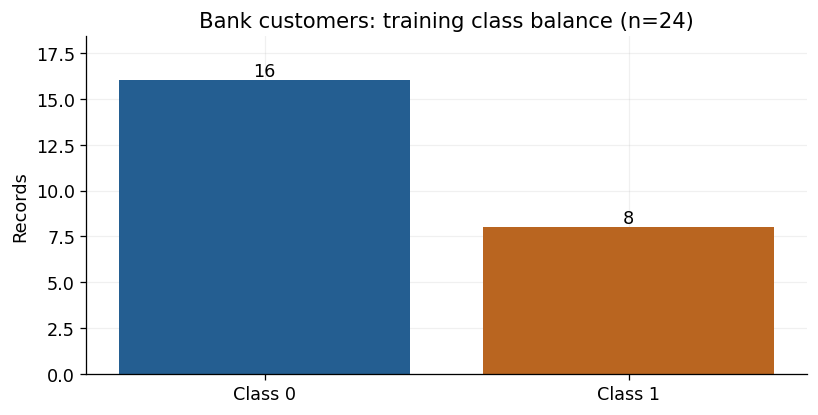

In [25]:
plot_label={'Loan_Default.csv':'Loan Default','accepted_2007_to_2018Q4.csv':'LendingClub','bank_customers.csv':'Bank customers'}[dataset_name]
train_index, valid_index, test_index, dev_index, folds = extra_split(X, y, groups, classification=True)
X_train, X_valid, X_test = [X.iloc[i] for i in [train_index, valid_index, test_index]]
y_train, y_valid, y_test = [y.iloc[i] for i in [train_index, valid_index, test_index]]
assert not (set(train_index)&set(valid_index) or set(train_index)&set(test_index) or set(valid_index)&set(test_index))
split_table = pd.DataFrame([{'Partition':label, 'Records':len(idx),
    'Class 0':int((y.iloc[idx]==0).sum()), 'Class 1':int(y.iloc[idx].sum()),
    'Positive share':y.iloc[idx].mean(),
    'Groups':len(idx) if groups is None else groups.iloc[idx].nunique()}
    for label,idx in [('Train',train_index),('Validation',valid_index),('Test',test_index)]])
display(split_table.set_index('Partition'))
display(X_train.isna().mean().mul(100).rename('Training missing (%)').to_frame())
display(X_train[numeric].agg(['min','median','max']))
fig,ax=plt.subplots(figsize=(7,3.5),layout='constrained')
counts=y_train.value_counts().reindex([0,1],fill_value=0)
ax.bar(['Class 0','Class 1'], counts, color=[BLUE,ORANGE])
for j,v in enumerate(counts): ax.text(j,v,f'{v:,}',ha='center',va='bottom')
ax.set(title=f'{plot_label}: training class balance (n={len(y_train):,})',ylabel='Records',ylim=(0,counts.max()*1.15))
plt.show()

### C3. Tune each model family on training folds

The independent validation set selects among tuned families; test outcomes do not enter selection.

In [26]:
specifications = {
    'Linear SVM': (SVC(kernel='linear', cache_size=512), {'model__C':[0.01,0.1,1]}),
    'RBF SVM': (SVC(kernel='rbf', cache_size=512),
                {'model__C':[0.1,1,10], 'model__gamma':['scale',0.01]}),
    'Polynomial SVM': (SVC(kernel='poly', degree=2, coef0=1, cache_size=512),
                       {'model__C':[0.01,0.1,1]})}
searches={}; rows=[]
for name,(model,grid) in specifications.items():
    searches[name],row=tune(model,grid)
    rows.append({'Model':name,**row})
comparison=pd.DataFrame(rows).set_index('Model')
fitted={name:search.best_estimator_ for name,search in searches.items()}
chosen_name=comparison['Validation AUC'].idxmax() # fixed insertion order breaks ties
selected=fitted[chosen_name]
display(comparison.drop(columns='Parameters'))
display(pd.DataFrame([{'Model':name,'Parameter':key.removeprefix('model__'),'Value':str(value)}
    for name,search in searches.items() for key,value in search.best_params_.items()]))
display(Markdown(f'Validation selected **{chosen_name}**. CV standard deviations describe fold variation, '
    'not confidence intervals. A bounded grid is a teaching experiment, not an exhaustive optimum.'))

,CV AUC,CV AUC SD,Train AUC,Validation AUC,Validation AP,Fit seconds
Model,,,,,,
Linear SVM,0.5000,0.2453,0.5547,0.6000,0.4500,0.0498
RBF SVM,0.3889,0.1571,0.4844,0.5000,0.4167,0.1167
Polynomial SVM,0.3125,0.1115,0.5469,0.7000,0.7000,0.0508


,Model,Parameter,Value
0,Linear SVM,C,0.01
1,RBF SVM,C,1
2,RBF SVM,gamma,0.01
3,Polynomial SVM,C,1


Validation selected **Polynomial SVM**. CV standard deviations describe fold variation, not confidence intervals. A bounded grid is a teaching experiment, not an exhaustive optimum.

### C4. Inspect regularization and complexity

Fold-to-fold variation is descriptive, not an independent-experiment confidence interval.

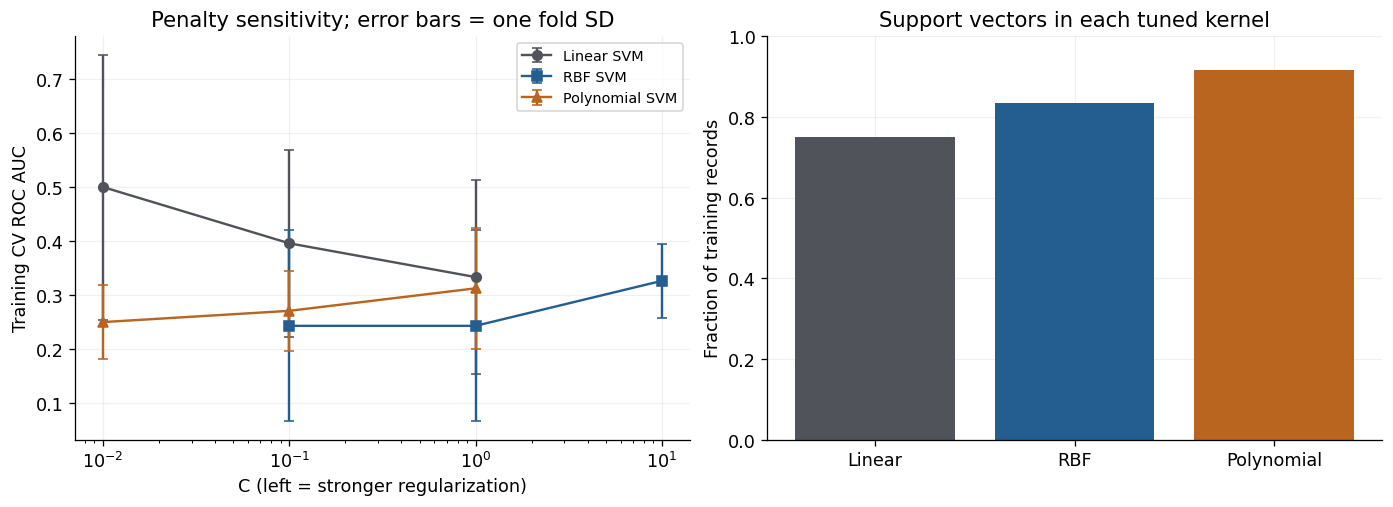

,Model,C,Support class 0,Support class 1
0,Linear SVM,0.0100,10,8
1,RBF SVM,1.0000,12,8
2,Polynomial SVM,1.0000,14,8


In [27]:
fig,axes=plt.subplots(1,2,figsize=(12,4.3),layout='constrained')
for name,color,marker in [('Linear SVM',GRAY,'o'),('RBF SVM',BLUE,'s'),('Polynomial SVM',ORANGE,'^')]:
    cv=pd.DataFrame(searches[name].cv_results_)
    if name=='RBF SVM': cv=cv[cv['param_model__gamma'].eq('scale')]
    cv=cv.sort_values('param_model__C')
    axes[0].errorbar(cv['param_model__C'].astype(float),cv['mean_test_auc'],
        yerr=cv['std_test_auc'],marker=marker,color=color,label=name,capsize=3)
    support=fitted[name].named_steps['model'].n_support_
    axes[1].bar(name.replace(' SVM',''),support.sum()/len(y_train),color=color)
axes[0].set(xscale='log',xlabel='C (left = stronger regularization)',ylabel='Training CV ROC AUC',
    title='Penalty sensitivity; error bars = one fold SD')
axes[0].legend(fontsize=9)
axes[1].set(ylim=(0,1),ylabel='Fraction of training records',title='Support vectors in each tuned kernel')
plt.show()
display(pd.DataFrame([{'Model':name,'C':m.named_steps['model'].C,
    'Support class 0':m.named_steps['model'].n_support_[0],
    'Support class 1':m.named_steps['model'].n_support_[1]} for name,m in fitted.items()]))

### C5. Visualize the kernel trick on this dataset

These auxiliary two-feature classifiers use fixed settings and training data only. Their plots illustrate geometry, not the tuned full-feature model’s performance. Points outside the central view remain in fitting.

Balanced class penalties make both classes visible in this geometric illustration. This fixed illustrative setting is distinct from the original unweighted model-selection experiment and from the later tuned balanced sensitivity check.

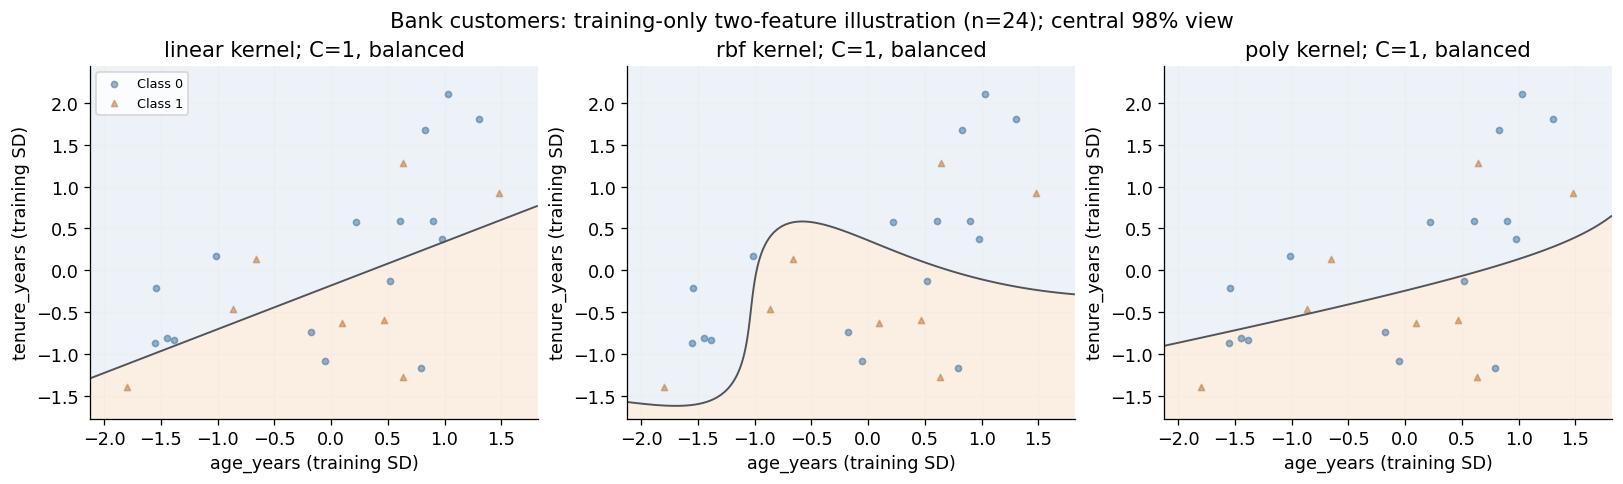

In [28]:
# Ancillary two-feature illustration uses only training data and fixed C=1.
# It is distinct from the tuned full-feature models and supplies no test metric.
plot_features = (['fico_mid','dti'] if 'fico_mid' in numeric else
                 ['loan_amount','Credit_Score'] if 'Credit_Score' in numeric else numeric[:2])
plot_X=X_train[plot_features]
if len(plot_X)>1500: plot_X=plot_X.sample(1500,random_state=SEED)
plot_y=y_train.loc[plot_X.index]
plot_prepare=Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())])
Z=plot_prepare.fit_transform(plot_X)
lo,hi=np.quantile(Z,[0.01,0.99],axis=0)
pad=np.maximum((hi-lo)*0.12,0.2); lo-=pad; hi+=pad
xx,yy=np.meshgrid(np.linspace(lo[0],hi[0],120),np.linspace(lo[1],hi[1],120))
grid=np.c_[xx.ravel(),yy.ravel()]
fig,axes=plt.subplots(1,3,figsize=(14,4.1),layout='constrained')
for ax,kernel in zip(axes,['linear','rbf','poly']):
    demo=SVC(kernel=kernel,C=1,degree=2,coef0=1,class_weight='balanced').fit(Z,plot_y)
    zz=demo.decision_function(grid).reshape(xx.shape)
    ax.contourf(xx,yy,zz,levels=[-np.inf,0,np.inf],colors=['#E8EFF5','#FAEADD'],alpha=0.8)
    if zz.min()<0<zz.max(): ax.contour(xx,yy,zz,levels=[0],colors=GRAY,linewidths=1.2)
    for label,color,marker in [(0,BLUE,'o'),(1,ORANGE,'^')]:
        mask=plot_y.to_numpy()==label
        ax.scatter(Z[mask,0],Z[mask,1],c=color,marker=marker,s=15,alpha=0.45,label=f'Class {label}')
    ax.set(xlim=(lo[0],hi[0]),ylim=(lo[1],hi[1]),title=f'{kernel} kernel; C=1, balanced',
        xlabel=plot_features[0]+' (training SD)',ylabel=plot_features[1]+' (training SD)')
axes[0].legend(fontsize=8)
fig.suptitle(f'{plot_label}: training-only two-feature illustration (n={len(Z):,}); central 98% view')
plt.show()

### Choose a validation operating rule

Search validation-score quantiles for F1. A greater cutoff breaks F1 ties. This teaching objective is not a specified business cost function.

The plot zooms to the observed validation-score range so nearly constant margins remain visible. The conventional cutoff is still assessed in the table even when it lies outside that range.

,ROC AUC,Average precision,Accuracy,Balanced accuracy,Precision,Recall,F1,Predicted positive
Rule,,,,,,,,
Default,0.7000,0.7000,0.7143,0.5000,0.0000,0.0000,0.0000,0
Validation F1,0.7000,0.7000,0.8571,0.7500,1.0000,0.5000,0.6667,1


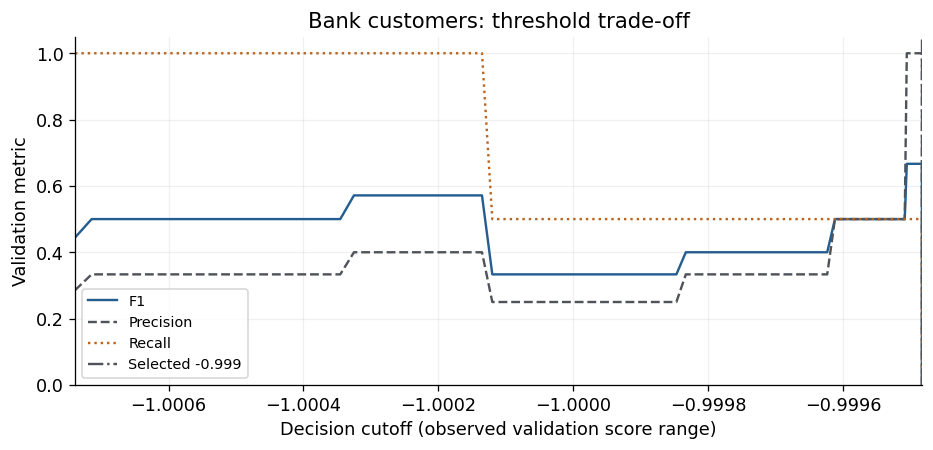

In [29]:
# Select an operating rule on validation only. Include the conventional model cutoff.
validation_scores=score_values(selected,X_valid)
default_cutoff=0.0 if hasattr(selected,'decision_function') else 0.5
cutoffs=np.unique(np.r_[np.quantile(validation_scores,np.linspace(0,1,101)),default_cutoff,
    np.nextafter(validation_scores.max(),np.inf)])
threshold_table=pd.DataFrame([{'Cutoff':t,'F1':f1_score(y_valid,validation_scores>=t,zero_division=0),
    'Precision':precision_score(y_valid,validation_scores>=t,zero_division=0),
    'Recall':recall_score(y_valid,validation_scores>=t,zero_division=0)} for t in cutoffs])
# F1 ties use the greatest cutoff, a prespecified conservative tie rule.
best=threshold_table.sort_values(['F1','Cutoff'],ascending=[False,False]).iloc[0]
chosen_cutoff=float(best['Cutoff'])
display(pd.DataFrame([{'Rule':'Default',**metrics(y_valid,validation_scores,validation_scores>=default_cutoff)},
    {'Rule':'Validation F1',**metrics(y_valid,validation_scores,validation_scores>=chosen_cutoff)}]).set_index('Rule'))
fig,ax=plt.subplots(figsize=(8,3.8),layout='constrained')
for metric,color,style in [('F1',BLUE,'-'),('Precision',GRAY,'--'),('Recall',ORANGE,':')]:
    ax.plot(threshold_table['Cutoff'],threshold_table[metric],label=metric,color=color,linestyle=style)
ax.axvline(chosen_cutoff,color=GRAY,linestyle='-.',label=f'Selected {chosen_cutoff:.3g}')
ax.set(xlabel='Decision cutoff (model score units)',ylabel='Validation metric',ylim=(0,1.05),
    title=f'{plot_label}: threshold trade-off')
ax.set_xlim(float(validation_scores.min()),float(validation_scores.max()))
ax.ticklabel_format(axis='x',style='plain',useOffset=False)
ax.set_xlabel('Decision cutoff (observed validation score range)')
ax.legend(fontsize=9);plt.show()

### Results: evaluate the frozen models once

All candidate families were declared in advance. Test rows report evidence, not a second opportunity to select a family. Default-cutoff rows and the selected validation-cutoff row distinguish ranking from decision quality.

In [30]:
# Freeze training-fitted estimators: no refit, so the selected score cutoff stays on its original scale.
logistic=pipeline(LogisticRegression(C=1,max_iter=10000)).fit(X_train,y_train)
dummy=DummyClassifier(strategy='prior').fit(X_train,y_train)
test_models={**fitted,'Logistic baseline':logistic,'Prevalence baseline':dummy}
test_rows=[]
for name,model in test_models.items():
    scores=score_values(model,X_test)
    prediction=model.predict(X_test)
    test_rows.append({'Model':name,**metrics(y_test,scores,prediction)})
test_scores=score_values(selected,X_test)
test_prediction=test_scores>=chosen_cutoff
test_rows.append({'Model':chosen_name+' (validation F1 cutoff)',**metrics(y_test,test_scores,test_prediction)})
test_table=pd.DataFrame(test_rows).set_index('Model')
display(test_table)
# Assertions independently reconcile the selected confusion counts and rank metric.
cm=confusion_matrix(y_test,test_prediction,labels=[0,1])
assert cm.sum()==len(y_test) and cm[1].sum()==y_test.sum()
assert np.isclose(roc_auc_score(y_test,test_scores),test_table.loc[chosen_name,'ROC AUC'])
# Stratified row bootstrap: descriptive conditional uncertainty for the two loan samples only.
# Bank rows have grouped dependence and too few held-out accounts for a useful interval.
auc_interval=None
if groups is None:
    rng_ci=np.random.default_rng(SEED)
    yy_test=y_test.to_numpy(); neg=np.flatnonzero(yy_test==0); pos=np.flatnonzero(yy_test==1)
    draws=[]
    for _ in range(300):
        idx=np.r_[rng_ci.choice(neg,len(neg),replace=True),rng_ci.choice(pos,len(pos),replace=True)]
        draws.append(roc_auc_score(yy_test[idx],test_scores[idx]))
    auc_interval=np.quantile(draws,[0.025,0.975])
    print(f'95% stratified row-bootstrap AUC interval: [{auc_interval[0]:.3f}, {auc_interval[1]:.3f}]')
    print('Conditional on the fitted model, fixed class counts and row independence; excludes selection/training uncertainty.')
else:
    print('Bank test set: exact confusion counts are primary; no reliable population interval is claimed.')
results.append({'Dataset':dataset_name,'Outcome':outcome_label,'Selected':chosen_name,
    'Train n':len(y_train),'Validation n':len(y_valid),'Test n':len(y_test),
    'ROC AUC':roc_auc_score(y_test,test_scores),'Average precision':average_precision_score(y_test,test_scores),
    'Test positive share':y_test.mean(),'F1 (validation cutoff)':f1_score(y_test,test_prediction,zero_division=0),
    'Cutoff':chosen_cutoff})

,ROC AUC,Average precision,Accuracy,Balanced accuracy,Precision,Recall,F1,Predicted positive
Model,,,,,,,,
Linear SVM,0.7500,0.9306,0.2500,0.5000,0.0000,0.0000,0.0000,0
RBF SVM,0.5000,0.7345,0.2500,0.5000,0.0000,0.0000,0.0000,0
Polynomial SVM,0.6667,0.9107,0.2500,0.5000,0.0000,0.0000,0.0000,0
Logistic baseline,0.5833,0.8179,0.2500,0.5000,0.0000,0.0000,0.0000,0
Prevalence baseline,0.5000,0.7500,0.2500,0.5000,0.0000,0.0000,0.0000,0
Polynomial SVM (validation F1 cutoff),0.6667,0.9107,0.2500,0.5000,0.0000,0.0000,0.0000,0


Bank test set: exact confusion counts are primary; no reliable population interval is claimed.


### Inspect held-out ranking and errors

The precision–recall baseline is this test partition’s positive share. Confusion counts use the frozen validation F1 cutoff.

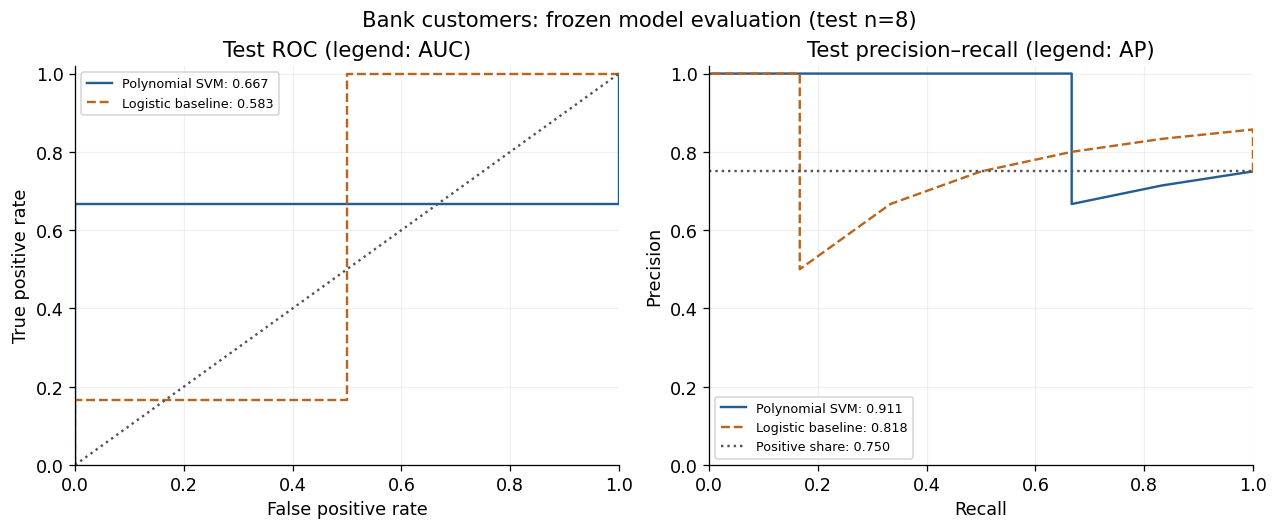

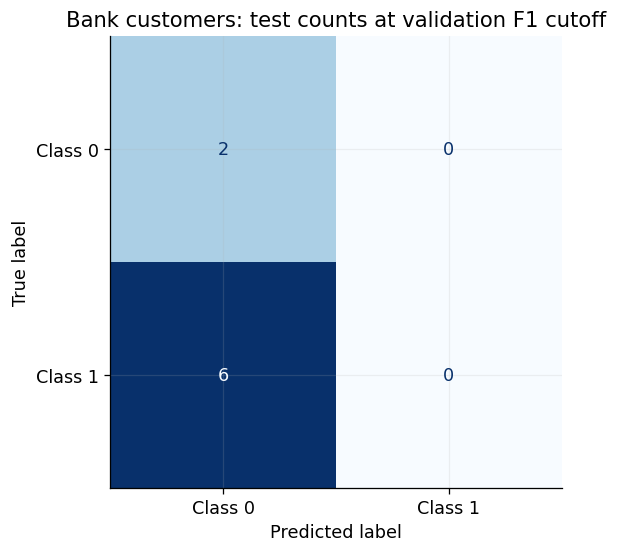

In [31]:
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
for name,model,color,style in [(chosen_name,selected,BLUE,'-'),('Logistic baseline',logistic,ORANGE,'--')]:
    scores=score_values(model,X_test)
    fpr,tpr,_=roc_curve(y_test,scores)
    precision,recall,_=precision_recall_curve(y_test,scores)
    axes[0].plot(fpr,tpr,color=color,linestyle=style,label=f'{name}: {roc_auc_score(y_test,scores):.3f}')
    axes[1].plot(recall,precision,color=color,linestyle=style,label=f'{name}: {average_precision_score(y_test,scores):.3f}')
axes[0].plot([0,1],[0,1],color=GRAY,linestyle=':')
axes[1].axhline(y_test.mean(),color=GRAY,linestyle=':',label=f'Positive share: {y_test.mean():.3f}')
axes[0].set(title='Test ROC (legend: AUC)',xlabel='False positive rate',ylabel='True positive rate',xlim=(0,1),ylim=(0,1.02))
axes[1].set(title='Test precision–recall (legend: AP)',xlabel='Recall',ylabel='Precision',xlim=(0,1),ylim=(0,1.02))
axes[0].legend(fontsize=8);axes[1].legend(fontsize=8)
fig.suptitle(f'{plot_label}: frozen model evaluation (test n={len(y_test):,})')
plt.show()
fig,ax=plt.subplots(figsize=(5.5,4.7),layout='constrained')
ConfusionMatrixDisplay(cm,display_labels=['Class 0','Class 1']).plot(ax=ax,colorbar=False,cmap='Blues')
ax.set_title(f'{plot_label}: test counts at validation F1 cutoff')
plt.show()

In [32]:
r=results[-1]
log_auc=test_table.loc['Logistic baseline','ROC AUC']
sv_note = (f"The selected kernel uses C={selected.named_steps['model'].C}; "
    f"{selected.named_steps['model'].n_support_.sum():,}/{len(y_train):,} training records are support vectors. "
    "The kernel comparison and CV penalty path show whether extra flexibility helped within this finite search."
    if hasattr(selected.named_steps['model'],'n_support_') else
    "The unrestricted-tree comparison exposes training optimism; CV complexity curves and held-out forest importance "
    "make the depth/variance trade-off inspectable. A forest is not guaranteed to beat a tuned single tree.")
caveat = ('Only eight bank test records support this estimate. One changed label or prediction can materially change it; '
    'checking status is an account attribute, not a credit-risk outcome.' if groups is not None else
    'These historical random-split results do not establish future-cohort accuracy or borrower independence. '
    'The loan outcome definitions and exclusions limit the population to which this result applies.')
display(Markdown(f'''### Dataset takeaways — {dataset_name}

Validation selected **{chosen_name}**; the frozen model has test ROC AUC **{r['ROC AUC']:.3f}** and average precision **{r['Average precision']:.3f}**, against test positive share **{r['Test positive share']:.3f}**. The prespecified logistic baseline has AUC **{log_auc:.3f}** (descriptive difference **{r['ROC AUC']-log_auc:+.3f}**, not a significance claim).

{sv_note}

The validation-selected operating rule yields test F1 **{r['F1 (validation cutoff)']:.3f}** and confusion counts TN={cm[0,0]}, FP={cm[0,1]}, FN={cm[1,0]}, TP={cm[1,1]}. F1 weights precision and recall equally and ignores true negatives; a deployed cutoff would require explicit costs. Validation F1 is optimistic because it selected this cutoff.

{caveat} These are associations. No causal, fairness, calibrated-risk or deployment claim is supported.
'''))

### Dataset takeaways — bank_customers.csv

Validation selected **Polynomial SVM**; the frozen model has test ROC AUC **0.667** and average precision **0.911**, against test positive share **0.750**. The prespecified logistic baseline has AUC **0.583** (descriptive difference **+0.083**, not a significance claim).

The selected kernel uses C=1; 22/24 training records are support vectors. The kernel comparison and CV penalty path show whether extra flexibility helped within this finite search.

The validation-selected operating rule yields test F1 **0.000** and confusion counts TN=2, FP=0, FN=6, TP=0. F1 weights precision and recall equally and ignores true negatives; a deployed cutoff would require explicit costs. Validation F1 is optimistic because it selected this cutoff.

Only eight bank test records support this estimate. One changed label or prediction can materially change it; checking status is an account attribute, not a credit-risk outcome. These are associations. No causal, fairness, calibrated-risk or deployment claim is supported.


**What this dataset teaches.** Validation contained only 2 positives among 7 records (28.6%); test contained 6 among 8 (75.0%). The selected polynomial SVM ranked test examples above chance (AUC 0.667) yet its validation cutoff predicted **zero** positives, missing all six checking accounts. Ranking and a transported decision rule answer different questions. The shift in tiny partition class mixes is observed here; it is not evidence of a population trend.

### Exploratory follow-up: class-specific margin penalties

The first completed run showed weak SVM ranking and majority-class decisions on the imbalanced lending sample. This follow-up checks one possible explanation on **training and validation only**. `class_weight='balanced'` replaces the common C by class-specific $C_k=C\,n/(2n_k)$, computed from each fitting fold. This increases the penalty for minority-class violations; it does not change the observed class prevalence or create probabilities.

Tune the balanced **linear** SVM on the original training folds and compare its validation ranking with the original linear model. This was added after the original run was inspected: it is exploratory, **does not replace the selected family or cutoff**, and receives **no additional test evaluation**. A fresh future holdout would be needed before promoting it as an improvement.

In [33]:
balanced_search, balanced_row=tune(SVC(kernel='linear',class_weight='balanced',cache_size=512),
    {'model__C':[0.01,0.1,1]})
sensitivity=pd.DataFrame([
    {'Linear penalty':'Unweighted',**comparison.loc['Linear SVM'].to_dict()},
    {'Linear penalty':'Balanced (exploratory)',**balanced_row}]).set_index('Linear penalty')
display(sensitivity[['CV AUC','CV AUC SD','Validation AUC','Validation AP','Parameters']])
margin=score_values(fitted['Linear SVM'],X_valid)
balanced_margin=score_values(balanced_search.best_estimator_,X_valid)
display(pd.DataFrame([
    {'Linear penalty':'Unweighted', 'Validation positives at margin 0':int((margin>=0).sum()),
     'Validation score SD':float(np.std(margin))},
    {'Linear penalty':'Balanced (exploratory)', 'Validation positives at margin 0':int((balanced_margin>=0).sum()),
     'Validation score SD':float(np.std(balanced_margin))}]).set_index('Linear penalty'))
delta=balanced_row['Validation AUC']-comparison.loc['Linear SVM','Validation AUC']
display(Markdown(f'Balanced penalties change validation AUC by **{delta:+.3f}** relative to the original linear SVM. '
    'Near-constant scores or very few positive decisions can occur when hinge loss favors a majority-class rule. '
    'This check does not establish the cause of every weak kernel result or validate a new final model.'))

,CV AUC,CV AUC SD,Validation AUC,Validation AP,Parameters
Linear penalty,,,,,
Unweighted,0.5000,0.2453,0.6000,0.4500,{'model__C': 0.01}
Balanced (exploratory),0.4097,0.2479,0.6000,0.4500,{'model__C': 0.01}


,Validation positives at margin 0,Validation score SD
Linear penalty,,
Unweighted,0,0.0004
Balanced (exploratory),6,0.0569


Balanced penalties change validation AUC by **+0.000** relative to the original linear SVM. Near-constant scores or very few positive decisions can occur when hinge loss favors a majority-class rule. This check does not establish the cause of every weak kernel result or validate a new final model.

## Results across all three datasets

Targets have different meanings. Compare models **within** a dataset; do not rank the datasets’ difficulty or business value by AUC.

In [34]:
all_results=pd.DataFrame(results).set_index('Dataset')
assert set(all_results.index)=={'Loan_Default.csv','accepted_2007_to_2018Q4.csv','bank_customers.csv'}
assert len(all_results)==3
display(all_results)
for row in results:
    display(Markdown(f"- **{row['Dataset']}** — {row['Outcome']}: **{row['Selected']}**, test AUC **{row['ROC AUC']:.3f}**, AP **{row['Average precision']:.3f}**, F1 at the validation cutoff **{row['F1 (validation cutoff)']:.3f}**, test n={row['Test n']:,}."))

,Outcome,Selected,Train n,Validation n,Test n,ROC AUC,Average precision,Test positive share,F1 (validation cutoff),Cutoff
Dataset,,,,,,,,,,
Loan_Default.csv,recorded Status 1,RBF SVM,7200,2400,2400,0.5900,0.3510,0.2367,0.3706,-0.9997
accepted_2007_to_2018Q4.csv,charged off among resolved 2015 36-month loans,Linear SVM,7200,2400,2400,0.5335,0.1725,0.1400,0.2393,-1.0001
bank_customers.csv,checking account versus savings/CD,Polynomial SVM,24,7,8,0.6667,0.9107,0.7500,0.0000,-0.9995


- **Loan_Default.csv** — recorded Status 1: **RBF SVM**, test AUC **0.590**, AP **0.351**, F1 at the validation cutoff **0.371**, test n=2,400.

- **accepted_2007_to_2018Q4.csv** — charged off among resolved 2015 36-month loans: **Linear SVM**, test AUC **0.534**, AP **0.172**, F1 at the validation cutoff **0.239**, test n=2,400.

- **bank_customers.csv** — checking account versus savings/CD: **Polynomial SVM**, test AUC **0.667**, AP **0.911**, F1 at the validation cutoff **0.000**, test n=8.

## Conclusions

The selected models answer three separate classification questions. Preserve the target definitions, cohorts, leakage audit, excluded records and sample sizes when compiling Milestone One. Use the saved test tables, complexity diagnostics and confusion counts as evidence; avoid choosing a new model because it looks best on a test chart.

The next useful validation would use a future lending vintage with known feature availability and mature outcomes, verify borrower/account identity, evaluate subgroup performance where appropriate data and sample sizes permit, and choose a cutoff using explicit decision costs. Loan_Default needs documented status timing. Bank modeling needs substantially more valid records and a target aligned with a real decision. These are proposed next steps, not completed validation.

No external data were added. Data provenance is the three local CSV paths and the explicit cohort/sampling audit above. The notebooks document observed historical associations rather than causal effects.

**F1 reasonableness check.** An always-positive rule has precision equal to positive share $p$, recall 1, and $F_1=2p/(1+p)$ (Loan_Default 0.383, LendingClub 0.246, bank 0.857). These are descriptive references derived from the test class counts, not newly trained or selected models. The selected unweighted SVM cutoffs do not exceed those F1 references on test. This exposes their limited decision value even where AUC exceeds 0.5.